<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_CertifiedRobustness_Guan2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN certified robustness under known-readout query access (KRQA): Guan and Huang (2026) step by step

**Paper.** Ji Guan and Mingyu Huang, *Certifying Adversarial Robustness of Quantum Classifiers under Known-Readout Query Access*, arXiv:2609.11637v2 [quant-ph], September 2026 (CCS 2026 artifact track). DOI [10.48550/arXiv.2609.11637](https://doi.org/10.48550/arxiv.2609.11637). Public artifact: [github.com/Veri-Q/KRQA-Robustness](https://github.com/Veri-Q/KRQA-Robustness), used here at the pinned commit `c9a36f57177d8f8f481cb93750a06473dc2b8a9c`.

**What this notebook does.** A deployed quantum classifier is a black box: you can send it inputs and read finite-shot measurement outcomes, you know the *readout* (the POVM that turns the measured register into class labels), but you cannot see the circuit, the parameters or the gradients. The paper shows how to sandwich the *robustness radius* of an input (the smallest fidelity distance to a state that is classified differently) between two certificates that are computed from measurement statistics only:

* a **lower bound** (Algorithm 2) that rules out any adversarial state inside the radius, and
* an **upper bound** (Algorithm 1) that proves that an adversarial state exists inside the radius, independent of any attack algorithm.

The notebook (1) fetches the authors' artifact at a pinned commit and verifies its frozen checkpoints, (2) re-implements both certification algorithms from the paper's text and cross-checks them against the authors' routine, (3) rebuilds the four 10-qubit simulation experiments (MNIST, Fashion-MNIST, cluster-excitation detection, and the spectral-box diagnostic) from raw data, (4) re-runs the 30-qubit matrix-product-state stress test in Qiskit Aer, (5) replays the archived IBM `ibm_kingston` raw counts, (6) trains its own classical baselines and its own quantum models, and (7) ends with a claim-by-claim comparison with the paper.

**How to run.** Open in Google Colab (CPU runtime is enough) and choose *Runtime -> Run all*. With `FAST_MODE = True` the notebook finishes in roughly 10 minutes (attacks on 5 inputs per task, shorter training); with `FAST_MODE = False` it follows the paper's 20-input protocol and takes about 35 minutes on 4 CPU cores. No account, API key or Hugging Face token is needed: MNIST, Fashion-MNIST and the authors' artifact are public. (If you adapt the notebook to a *gated* dataset, put your own token in Colab Secrets as `HF_TOKEN`; this notebook never prints or stores one.)

**What you get at the end.** Certified lower and upper robustness radii for 20 test inputs per task, side by side with random-search / FGSM / PGD attacks and a numerical white-box reference, the paper's figures re-drawn from our own numbers, and a table that says for every checkable claim whether it is reproduced.

## The paper in one page

**Problem.** A quantum classifier `Q = (H, U, {M_k})` evolves an input state `|psi>` with a unitary `U` and measures a POVM `{M_k}` (one effect per class). The predicted label is `t = argmax_k p_k` with `p_k = Tr[M_k U |psi><psi| U^dagger]`. The *robustness radius* is `eps*(psi) = inf { D_F(psi, phi) : Q(phi) != Q(psi) }` with fidelity distance `D_F(psi, phi) = 1 - |<psi|phi>|`.

**Access model (KRQA).** The evaluator can prepare inputs, knows the readout effects `{M_k}` and can request finite-shot outcomes of the native readout and of *binary projector readouts* derived from it. It cannot see `U`, the parameters or gradients.

**Method.**
* *Upper bound (Section 4, Algorithm 1).* For each competitor `k != t` split the gap operator `M_k - M_t = Delta+ - Delta-`. Any state in `supp(Delta+)`, pulled back through `U^dagger`, is an adversarial input. With `P_k` the projector onto `supp(Delta+)` and `p_k = Tr[P_k U psi U^dagger]` (one binary readout), `eps_RUB = 1 - max_k sqrt(p_k)`.
* *Lower bound (Section 5, Algorithm 2).* By monotonicity of fidelity, `D_F(psi, phi) >= 1 - sum_j sqrt(p_j q_j)` for the outcome distributions `p, q`. The unknown `q` is relaxed to the polytope `{sum q = 1, q_k >= q_t, lambda_min(M_j) <= q_j <= lambda_max(M_j)}`. The resulting concave program is bounded *from above* by a scalar Lagrange dual, so every number reported is a sound certificate. Without the spectral box this is the earlier closed-form bound of Guan et al. (CAV 2021).
* `eps_RLB <= eps* <= eps_RUB`, with finite-sample (Hoeffding) control of the probability estimates.

**Data and models.** 10-qubit QNNs (amplitude encoding of the 28x28 image, `StronglyEntanglingLayers`, Adam): MNIST digits 0-3 (800 train / 200 test, 4 layers), Fashion-MNIST classes 0-3 (1600 / 400, 6 layers), and a generated cluster-state excitation task (1000 / 200, 8 layers). A separate class-3-focused MNIST model with an amplified diagonal readout (27.5% accuracy) shows the spectral box at work. An untrained 30-qubit QNN (Aer matrix-product state) tests scalability, and two 8-qubit binary QNNs were run on `ibm_kingston` (40 circuits x 4096 shots).

**Claims.** Test accuracies 91.5% / 85.25% / 99.5% (Section 6); mean kernel upper bounds 0.3166 / 0.3019 / 0.4007 and mean lower bounds 1.1583e-3 / 1.2822e-3 / 7.7161e-3; the lower bound equals the probability-only bound on standard models but is 10.194x larger on the diagnostic (6.165e-2 vs 6.048e-3); `eps_RLB <= reference <= eps_RUB` on every retained input; FGSM / PGD find witnesses for 75% / 80% of MNIST inputs, 30% / 30% of Fashion-MNIST inputs and 0% of cluster inputs, where the kernel bound is still non-trivial; Example 5.4 gives `[7.21e-3, 0.368]` around the exact `0.120`; the 30-qubit mean bounds are 2.966e-5 and 0.4549; the IBM mean pairs are `[0.0034, 0.3513]` and `[0.0066, 0.3747]`.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | Abstract and references mention Qiskit and TensorFlow Quantum; Appendix J names `StronglyEntanglingLayers` and `AmplitudeEmbedding` (PennyLane names) | PennyLane 0.45.1 + PyTorch for the 10-qubit models (what the public artifact uses; TensorFlow Quantum is not needed and not installable on Colab CPU), Qiskit 2.5.2 / Aer for the 30-qubit MPS run, the QPY hardware circuits and a Qiskit re-expression with an equivalence assertion |
| Readout POVMs | Only "known native label POVM" is stated; the numbers depend on a specific non-projective readout | The artifact's frozen randomized-basis POVMs (strength 0.05 / 0.10 / 0.15, seeds 4 / 2 / 0) are rebuilt from their generator and asserted equal to the saved `selected_povm.npz` files (`# CHOICE:` taken from the artifact) |
| Trained weights | Adam, no epochs / learning rate in the text | Primary results use the authors' frozen checkpoints (SHA-256 verified). We also train our own MNIST model: the artifact config (lr 0.03, 20 epochs) and a tuned run (lr 0.1, 30 epochs) |
| Data subsets | "800 train / 200 test", digits 0-3 | Drawn with the authors' seeds (7 / 11 / 13) through `torch.randperm`; we assert that the 20 retained inputs equal the authors' `selected_sample_indices.csv` |
| Attacks | "fixed budget" random search, FGSM, PGD | Artifact settings: eps in {0.01, 0.02, 0.05}, 20 random trials, PGD 10 steps of eps/5 with random start, closest success kept (`# CHOICE:`) |
| Reporting rule | 20 correctly classified inputs in seeded random order with both `eps_RLB` and reference >= 5e-4 | Implemented as described, `sample_seed = 44` from the artifact config |
| Numerical reference | Density-matrix SLSQP, residual <= 1e-6, "not a proved global optimum" | Same; by Uhlmann's theorem it is exact when the environment can purify the output register, which holds here |
| Cluster data | "labelled by excitation-angle regime" | Artifact generator: `H` layer, `CZ` chain, `RX(theta)` on all qubits; class 0 if `abs(theta) < pi/2` else class 1 (generated with the physical protocol, not invented labels) |
| 30-qubit run | "untrained 30-qubit QNN, Aer MPS, 4096 shots" | Artifact circuit: `RY` input angles, 4 layers of `Rz Ry Rz` plus nearest-neighbour `CX` (not the PennyLane ring), smoothed computational readout (strength 0.2) |
| IBM hardware | `ibm_kingston`, 40 circuits | Cannot be re-run here. We replay the archived raw counts and recompute every certificate, interval and the 8-qubit accuracies from the stored weights |
| Dataset "HAI" | Listed in the corpus index for this paper | Not used: the paper's experiments use MNIST, Fashion-MNIST and generated cluster states only |

In [1]:
# Install (Colab or a fresh local environment). Pinned to the versions this notebook was tested with.
# Colab already ships numpy, pandas, scikit-learn, matplotlib, torch, torchvision, PyYAML, requests.
# If pip reports that a package was upgraded, restart the runtime once and run all cells again.
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("pennylane", "qiskit", "qiskit_aer", "torch", "torchvision", "yaml", "pylatexenc"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1",
                    "qiskit==2.5.2", "qiskit-aer==0.17.2", "pylatexenc", "pyyaml"], check=True)
    print("packages installed")
else:
    print("all required packages are already available")

all required packages are already available


In [2]:
# Configuration: every tunable constant lives here.
T0 = __import__("time").time()   # wall-clock start of the run
SEED = 42                      # global seed (data subsets use the authors' per-task seeds, see TASK_SEEDS)
FAST_MODE = False                # True: ~10 minute demo (5 attacked inputs per task, short training); False: paper protocol
DATA_DIR = "krqa_data"          # downloads and the cloned artifact are cached here
IBM_TOKEN = ""                  # optional; live IBM hardware is NOT used by this notebook (see section on the IBM replay)

REPO_URL = "https://github.com/Veri-Q/KRQA-Robustness.git"
PINNED_COMMIT = "c9a36f57177d8f8f481cb93750a06473dc2b8a9c"    # artifact version used throughout

N_RETAIN = 20                   # inputs per task, as in the paper
SHOTS = 4096                    # shots behind the finite-shot intervals (paper: 4096)
N_REPLICAS = 100 if FAST_MODE else 200        # parametric replicas per interval (paper: 200)
ATTACK_EPS = [0.01, 0.02, 0.05]               # CHOICE: attack budgets taken from the artifact config
N_ATTACK = 5 if FAST_MODE else N_RETAIN       # inputs per task on which the three attacks are run
N_SOUNDNESS = 12 if FAST_MODE else 40         # random small classifiers in the soundness test
N_KRQA_DEMO = 4 if FAST_MODE else 8           # inputs in the KRQA black-box demonstration

# Our own MNIST training runs (the artifact ships frozen weights; we also retrain, CHOICE below)
TRAIN_CONFIG = dict(epochs=3 if FAST_MODE else 20, lr=0.03)           # artifact config: lr 0.03, 20 epochs
TRAIN_TUNED = None if FAST_MODE else dict(epochs=30, lr=0.1)          # CHOICE: faster-converging schedule
TASK_SEEDS = dict(mnist=7, fashion_mnist=11, cluster=13, lower_bound_demo=7)   # from the artifact configs
SAMPLE_SEED = 44                # order in which correctly classified test inputs are inspected
REPORT_FLOOR = 5e-4             # inputs with eps_RLB or reference below this are skipped (paper, Section 6)
print(f"FAST_MODE={FAST_MODE}  N_ATTACK={N_ATTACK}  N_REPLICAS={N_REPLICAS}")

FAST_MODE=False  N_ATTACK=20  N_REPLICAS=200


In [3]:
import os, sys, math, json, time, pickle, hashlib, random, subprocess, warnings, io, zipfile, gzip, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import pennylane as qml
import scipy
from scipy.optimize import minimize, NonlinearConstraint
import sklearn, requests, yaml
import qiskit, qiskit_aer
from qiskit import QuantumCircuit, transpile, qpy
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from torchvision import datasets

warnings.filterwarnings("ignore", message=".*ComplexWarning.*")
warnings.filterwarnings("ignore", category=UserWarning, module="pennylane")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
DATA = Path(DATA_DIR); DATA.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.0.6
torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2
sklearn 1.9.1 | matplotlib 3.11.2


## Fetching the authors' artifact (pinned commit)

The artifact holds the frozen checkpoints and readouts behind the paper's tables, the released result tables, and the archived IBM raw counts. We clone it at a fixed commit (with a zip-download fallback) and **verify the SHA-256 of every frozen file against the hashes written in the artifact's own configuration files**. The artifact's weight files are Python pickles, so we load them with a restricted unpickler that only accepts NumPy array reconstruction; a pickle containing anything else is refused.

In [4]:
REPO = DATA / "KRQA-Robustness"

def fetch_artifact():
    if (REPO / "configs").exists():
        return "cached"
    try:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True, capture_output=True, timeout=900)
        subprocess.run(["git", "-C", str(REPO), "checkout", "-q", PINNED_COMMIT], check=True, capture_output=True)
        return "git"
    except Exception as exc:                                    # no git, or network policy: use the archive
        print("git clone failed (", type(exc).__name__, ") -> downloading the archive of the pinned commit")
        r = requests.get(f"https://github.com/Veri-Q/KRQA-Robustness/archive/{PINNED_COMMIT}.zip", timeout=900)
        r.raise_for_status()
        zipfile.ZipFile(io.BytesIO(r.content)).extractall(DATA)
        (DATA / f"KRQA-Robustness-{PINNED_COMMIT}").rename(REPO)
        return "zip"

how = fetch_artifact()
try:
    head = subprocess.run(["git", "-C", str(REPO), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
except Exception:
    head = ""
print("artifact obtained via:", how, "| HEAD:", head or "(no git metadata)")
if head:
    assert head == PINNED_COMMIT, "artifact is not at the pinned commit"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

class _NumpyOnlyUnpickler(pickle.Unpickler):
    _ALLOWED = {("numpy.core.multiarray", "_reconstruct"), ("numpy._core.multiarray", "_reconstruct"),
                ("numpy", "ndarray"), ("numpy", "dtype"),
                ("numpy.core.multiarray", "scalar"), ("numpy._core.multiarray", "scalar")}
    def find_class(self, module, name):
        if (module, name) in self._ALLOWED:
            return super().find_class(module, name)
        raise pickle.UnpicklingError(f"refused to unpickle {module}.{name}")

def load_weights_file(path):
    with open(path, "rb") as fh:
        return np.asarray(_NumpyOnlyUnpickler(fh).load(), dtype=np.float32)

CFG = {name: yaml.safe_load((REPO / "configs" / f"{name}.yaml").read_text()) for name in
       ("mnist", "fashion_mnist", "cluster", "lower_bound_demo")}
rows = []
for name, cfg in CFG.items():
    wpath, ppath = REPO / cfg["frozen_weights_path"], REPO / cfg["fixed_measurement"]["artifact"]
    rows.append(dict(task=name, weights_ok=sha256(wpath) == cfg["frozen_weights_sha256"],
                     povm_ok=sha256(ppath) == cfg["fixed_measurement"]["sha256"],
                     weight_shape=load_weights_file(wpath).shape, readout=cfg["fixed_measurement"]["family"]))
print(pd.DataFrame(rows).to_string(index=False))
assert all(r["weights_ok"] and r["povm_ok"] for r in rows), "a frozen artifact file does not match its recorded hash"

artifact obtained via: cached | HEAD: c9a36f57177d8f8f481cb93750a06473dc2b8a9c
            task  weights_ok  povm_ok weight_shape                       readout
           mnist        True     True   (4, 10, 3)              randomized_basis
   fashion_mnist        True     True   (6, 10, 3)              randomized_basis
         cluster        True     True   (8, 10, 3)              randomized_basis
lower_bound_demo        True     True   (4, 10, 3) amplified_four_class_diagonal


## Certification algorithms, written from the paper

Everything below is our own implementation of the paper's Sections 4 and 5; the artifact is used only to cross-check it. The same small functions serve every experiment.

### Readouts (POVMs)

A readout is a list of Hermitian effects `E_0 ... E_{C-1}`, `E_k >= 0`, `sum_k E_k = I`, acting on the measured register (2 qubits for the 4-class tasks, 1 qubit for the cluster task). On the whole system the effect is `E_k (x) I_env`, so spectra and positive gap subspaces are those of the small matrices.

In [5]:
# ---------------------------------------------------------------------------
# Readouts (POVMs).  A readout is a list of C Hermitian effects E_0..E_{C-1}
# with E_k >= 0 and sum_k E_k = I, acting on the d-dimensional output register.
# The full-system effect is E_k (x) I_env, so spectra and positive gap subspaces
# are the same as for the small d x d matrices.
# ---------------------------------------------------------------------------
def haar_unitary(dim, rng):
    z = rng.normal(size=(dim, dim)) + 1j * rng.normal(size=(dim, dim))
    q, r = np.linalg.qr(z)
    ph = np.diag(r)
    return q * (ph / np.maximum(np.abs(ph), 1e-12))


def randomized_basis_povm(n_classes, n_bases=3, strength=0.25, seed=0):
    """Mixture of the computational basis (weight 1-s) and random rotated bases
    with random class relabellings (weight s/(n_bases-1) each); same construction
    as the authors' artifact (experiments/measurement.py)."""
    rng = np.random.default_rng(seed)
    weights = np.array([1.0 - strength] + [strength / (n_bases - 1)] * (n_bases - 1))
    unitaries = [np.eye(n_classes, dtype=complex)]
    maps = [np.arange(n_classes)]
    for _ in range(n_bases - 1):
        unitaries.append(haar_unitary(n_classes, rng))
        maps.append(rng.permutation(n_classes))
    effects = [np.zeros((n_classes, n_classes), dtype=complex) for _ in range(n_classes)]
    for w, U, cmap in zip(weights, unitaries, maps):
        for outcome, cls in enumerate(cmap):
            ket = U[:, outcome:outcome + 1]
            effects[int(cls)] += w * (ket @ ket.conj().T)
    return effects


def smoothed_computational_povm(n_classes, strength=0.2):
    """E_j = (1-s)|j><j| + s/C * I  (label smoothing; diagonal, non-projective)."""
    I = np.eye(n_classes, dtype=complex)
    return [(1 - strength) * np.diag(I[j]) + strength / n_classes * I for j in range(n_classes)]


def amplified_diagonal_povm():
    """The four-class diagonal readout of the paper's lower-bound diagnostic
    (class 3 has a tight spectral box [0.4900, 0.4930])."""
    diag = np.array([[0.50, 0.20, 0.50, 0.06],
                     [0.0035, 0.1550, 0.0035, 0.2235],
                     [0.0035, 0.1550, 0.0035, 0.2235],
                     [0.4930, 0.4900, 0.4930, 0.4930]])
    return [np.diag(r).astype(complex) for r in diag]


def validate_povm(effects, atol=1e-8):
    mats = [np.asarray(E, dtype=complex) for E in effects]
    d = mats[0].shape[0]
    herm = max(np.linalg.norm(E - E.conj().T) for E in mats)
    mineig = min(np.linalg.eigvalsh(0.5 * (E + E.conj().T)).min() for E in mats)
    comp = np.linalg.norm(sum(mats) - np.eye(d))
    return dict(valid=bool(herm <= atol and mineig >= -atol and comp <= atol),
                min_eigenvalue=float(mineig), completeness_error=float(comp))


def spectral_box(effects):
    """a_j = lambda_min(E_j), b_j = lambda_max(E_j)  (the 'spectral box' of Eq. (3))."""
    ev = [np.linalg.eigvalsh(0.5 * (E + E.conj().T)) for E in effects]
    return np.array([e.min() for e in ev]), np.array([e.max() for e in ev])

### Lower bound (Algorithm 2)

For every competitor `k` the program `max_q sum_j sqrt(p_j q_j)` over the polytope `{sum q = 1, q_k >= q_t, a_j <= q_j <= b_j}` (`a_j = lambda_min(M_j)`, `b_j = lambda_max(M_j)`) is concave. Reporting the objective at an approximate primal point would give a *lower* bound on the maximum, which is useless for a certificate. The paper (Appendix G) instead evaluates the scalar Lagrange dual, which upper-bounds the maximum for **every** multiplier, so an unfinished bisection can only make the certificate weaker, never unsound. If the unconstrained box-simplex optimiser provably violates `q_k >= q_t`, the optimum lies on the tie face `q_k = q_t`; grouping those two coordinates gives another box-simplex problem. The probability-only closed form of Guan et al. (2021) is computed alongside and the larger of the two is reported.

In [6]:
# ---------------------------------------------------------------------------
# Lower bound (Section 5, Algorithm 2).
#   eps_RLB = 1 - max_{k != t} max_{q in P_{k->t}}  sum_j sqrt(p_j q_j)
#   P_{k->t} = { q : sum q = 1, q_k >= q_t, a_j <= q_j <= b_j }
# The inner problem is a concave maximisation.  To keep the certificate sound we
# never trust an approximate primal point; we evaluate the scalar Lagrange dual
#   g(lam) = lam + sum_j max_{a_j<=r_j<=b_j} ( sqrt(w_j r_j) - lam r_j )
# which upper-bounds the optimum for EVERY lam (weak duality).
# ---------------------------------------------------------------------------
def prior_lower_bound(p, t):
    """Probability-only comparator of [15]: 1 - sqrt(1 - (sqrt(p_t) - max_k sqrt(p_k))^2 / 2)."""
    p = np.asarray(p, float)
    pk = np.max(np.delete(p, t))
    gap = max(0.0, np.sqrt(p[t]) - np.sqrt(pk))
    return float(1.0 - np.sqrt(max(0.0, 1.0 - 0.5 * gap * gap)))


def _r_star(w, lo, hi, lam):
    """argmax_{lo<=r<=hi} sqrt(w r) - lam r  (closed form, Eq. (8) of the paper)."""
    if lam <= 0:
        return hi.copy()
    return np.clip(w / (4.0 * lam * lam), lo, hi)


def _dual_value(w, lo, hi, lam):
    r = _r_star(w, lo, hi, lam)
    val = lam + float(np.sum(np.sqrt(np.maximum(w * r, 0.0)) - lam * r))
    guard = 128 * np.finfo(float).eps * (len(w) + 4) * max(1.0, abs(lam) + abs(val))
    return min(val + guard, np.sqrt(max(float(w.sum()), 0.0)) + guard, 1.0)


def box_simplex_dual(w, lo, hi):
    """Certified upper bound on max { sum sqrt(w_i r_i) : sum r = 1, lo <= r <= hi }
    plus an interval enclosure of the maximiser.  Returns None if the set is empty."""
    w, lo, hi = (np.asarray(v, float) for v in (w, lo, hi))
    if np.any(lo > hi) or lo.sum() > 1.0 or hi.sum() < 1.0:
        return None
    lam_lo, lam_hi = -1.0, 1.0
    for _ in range(1100):                       # bracket: mass(lam_hi) <= 1
        if _r_star(w, lo, hi, lam_hi).sum() <= 1.0:
            break
        lam_hi *= 2.0
    for _ in range(200):                        # bisection on the normalisation
        mid = 0.5 * (lam_lo + lam_hi)
        mass = _r_star(w, lo, hi, mid).sum()
        if mass > 1.0:
            lam_lo = mid
        else:
            lam_hi = mid
    mid = 0.5 * (lam_lo + lam_hi)
    value = min(_dual_value(w, lo, hi, l) for l in (lam_lo, mid, lam_hi))
    r1, r2 = _r_star(w, lo, hi, lam_lo), _r_star(w, lo, hi, lam_hi)
    guard = 2e-12
    return value, np.maximum(lo, np.minimum(r1, r2) - guard), np.minimum(hi, np.maximum(r1, r2) + guard)


def spectral_lower_bound(p, t, a, b):
    """Spectral-box lower bound on the robustness radius (Theorem 5.3 + Appendix G)."""
    p = np.asarray(p, float); p = p / p.sum()
    if np.max(np.delete(p, t)) >= p[t]:
        return 0.0                              # nominal label lost or tied
    lo = np.clip(np.asarray(a, float) - 1e-12, 0, 1)
    hi = np.clip(np.asarray(b, float) + 1e-12, 0, 1)
    unc = box_simplex_dual(p, lo, hi)
    if unc is None:
        return 0.0
    v_unc, r_lo, r_hi = unc
    radii = []
    for k in range(len(p)):
        if k == t:
            continue
        if r_lo[t] <= r_hi[k]:                  # cannot certify q_k < q_t at the optimiser
            radii.append(1.0 - v_unc)           # conservative fallback
            continue
        rest = [j for j in range(len(p)) if j not in (t, k)]
        w0 = 0.5 * (np.sqrt(p[t]) + np.sqrt(p[k])) ** 2      # tie face q_t = q_k
        w = np.concatenate([[w0], p[rest]])
        l = np.concatenate([[2 * max(lo[t], lo[k])], lo[rest]])
        h = np.concatenate([[2 * min(hi[t], hi[k])], hi[rest]])
        tied = box_simplex_dual(w, l, h)
        radii.append(1.0 if tied is None else 1.0 - tied[0])  # empty polytope => no adversary
    return float(np.clip(min(radii), 0.0, 1.0))


def certified_lower_bound(p, t, a, b):
    """Algorithm 2: max of the spectral-box dual bound and the probability-only bound."""
    return max(spectral_lower_bound(p, t, a, b), prior_lower_bound(p, t))

### Upper bound (Algorithm 1)

For each competitor the positive part of the gap `M_k - M_t` defines a projector `P_k`. Measuring the *binary* readout `{P_k, I - P_k}` on the hidden evolved state gives `p_k`, the weight of the state inside the adversarial kernel space; the closest adversarial state in that space is at fidelity distance `1 - sqrt(p_k)`. Tie priority is handled as in the paper: a competitor that wins ties and has `lambda_max(M_k - M_t) = 0` yields the trivial witness radius 1.

In [7]:
# ---------------------------------------------------------------------------
# Upper bound (Section 4, Algorithm 1).
# For every competitor k != t, split the gap M_k - M_t = Delta+ - Delta- and let
# P_k be the projector onto supp(Delta+).  Then  eps_RUB = 1 - max_k sqrt(p_k)
# with p_k = Tr[P_k rho_out], i.e. the first outcome of the BINARY readout
# {P_k, I - P_k}.  Only that binary readout is needed (KRQA), not U.
# ---------------------------------------------------------------------------
def gap_projector(Mk, Mt, k_has_priority, tol=1e-10):
    G = Mk - Mt
    G = 0.5 * (G + G.conj().T)
    ev, V = np.linalg.eigh(G)
    guard = max(tol, 32 * np.finfo(float).eps * len(ev) * max(1.0, np.abs(ev).max()))
    pos = ev > guard
    if pos.any():
        B = V[:, pos]
        return "finite", B @ B.conj().T
    if k_has_priority and ev.max() >= -guard:
        return "tie", np.zeros_like(G)          # tie resolved against t => witness with radius 1
    return "robust", np.zeros_like(G)           # competitor can never win


def upper_projectors(effects, t):
    out = {}
    for k in range(len(effects)):
        if k != t:
            out[k] = gap_projector(effects[k], effects[t], k < t)
    return out


def upper_bound_from_overlaps(status_proj, overlaps):
    """eps_RUB = 1 - max_k sqrt(p_k) over competitors with a positive gap."""
    fin = {k: overlaps[k] for k, (s, _) in status_proj.items() if s == "finite"}
    if fin:
        k = max(fin, key=fin.get)
        return float(1.0 - np.sqrt(np.clip(fin[k], 0, 1))), k
    if any(s == "tie" for s, _ in status_proj.values()):
        return 1.0, None
    return float("inf"), None                   # unconditionally robust

### Numerical white-box reference and finite-shot intervals

The reference is **not** available under KRQA (it needs the state); it only serves to check that the certificates bracket something real. For a pure state on system + environment, Uhlmann's theorem turns the optimal adversarial state into an optimisation over the reduced density matrix of the readout register, a convex program that we solve with SciPy SLSQP exactly like the paper (successful termination and constraint residual <= 1e-6 required). The 95% intervals follow Section 6: `B` parametric replicas `Y ~ Multinomial(N, p)` of the outcome counts (nominal label fixed; a replica that loses or ties the label has lower radius 0) and `Z ~ Binomial(N, r)` for the kernel overlap `r`.

In [8]:
# ---------------------------------------------------------------------------
# Numerical white-box reference (needs the state, i.e. NOT available under KRQA).
# By Uhlmann's theorem the fidelity-optimal adversarial pure state on system+
# environment is found by optimising its reduced density matrix rho on the
# output register:   min 1 - F(sigma, rho)   s.t.  Tr[(E_k - E_t) rho] >= 0,
# F = Tr sqrt( sqrt(sigma) rho sqrt(sigma) ).  This is a convex problem; we solve it
# with SciPy SLSQP (as the paper does) and require a feasible, converged solve.
# ---------------------------------------------------------------------------
def _psd_sqrt(S):
    ev, V = np.linalg.eigh(0.5 * (S + S.conj().T))
    return (V * np.sqrt(np.clip(ev, 0, None))) @ V.conj().T


def numerical_reference(sigma, effects, t):
    d = sigma.shape[0]
    sq = _psd_sqrt(sigma + 1e-12 * np.eye(d))

    def to_rho(x):
        n = d * d
        M = x[:n].reshape(d, d) + 1j * x[n:].reshape(d, d)
        M = M / (np.sqrt(np.real(np.trace(M @ M.conj().T))) + 1e-12)
        return M @ M.conj().T

    x0m = np.linalg.cholesky(sigma + 1e-10 * np.eye(d))
    x0 = np.concatenate([x0m.real.ravel(), x0m.imag.ravel()])
    best = 1.0
    for k in range(len(effects)):
        if k == t:
            continue
        gap = effects[k] - effects[t]
        if np.linalg.eigvalsh(0.5 * (gap + gap.conj().T)).max() < -1e-10:
            continue                                         # k can never win
        fid = lambda x: float(np.clip(np.sum(np.sqrt(np.clip(np.linalg.eigvalsh(sq @ to_rho(x) @ sq), 0, None))), 0, 1))
        res = minimize(lambda x: 1.0 - fid(x), x0, method="SLSQP",
                       constraints=[NonlinearConstraint(lambda x: float(np.real(np.trace(gap @ to_rho(x)))), 0, np.inf)],
                       options={"ftol": 1e-8, "maxiter": 1000, "disp": False})
        resid = max(0.0, -float(np.real(np.trace(gap @ to_rho(res.x)))))
        if not res.success or resid > 1e-6:
            raise RuntimeError(f"reference solve failed for competitor {k}: {res.message}, residual {resid:.2e}")
        best = min(best, float(res.fun))
    return float(np.clip(best, 0.0, 1.0))

In [9]:
# ---------------------------------------------------------------------------
# Finite-shot 95 % intervals exactly as described in Section 6: B parametric
# replicas  Y ~ Multinomial(N, p)  (lower bound, nominal label t fixed) and
# Z ~ Binomial(N, r)  (kernel overlap r -> 1 - sqrt(Z/N)).
# ---------------------------------------------------------------------------
def multinomial_interval(p, fn, shots=4096, B=200, level=0.95, seed=0):
    rng = np.random.default_rng(seed)
    reps = rng.multinomial(shots, np.asarray(p, float) / np.sum(p), size=B) / shots
    vals = np.array([fn(r) for r in reps])
    q = (1 - level) / 2
    return float(np.quantile(vals, q)), float(np.quantile(vals, 1 - q))


def binomial_upper_interval(r, shots=4096, B=200, level=0.95, seed=0):
    rng = np.random.default_rng(seed)
    z = rng.binomial(shots, float(np.clip(r, 0, 1)), size=B) / shots
    vals = 1.0 - np.sqrt(z)
    q = (1 - level) / 2
    return float(np.quantile(vals, q)), float(np.quantile(vals, 1 - q))

### Worked example 3.2 / 4.9 / 5.4 (closed-form check of the paper's numbers)

A four-dimensional classifier with `U = I`, the diagonal POVM of Example 3.2 and `|psi> = sqrt(0.1)|0> + sqrt(0.2)|1> + sqrt(0.3)|2> + sqrt(0.4)|3>`. The paper reports `p = (0.240, 0.178, 0.233, 0.349)`, `eps_RUB = 0.368`, `eps_RLB = 7.21e-3` (against `2.55e-3` for the probability-only bound) and the exact radius `0.120` from the QCQP. With no environment the exact radius needs *pure* adversarial states, so we solve that QCQP with SLSQP from many random starts.

In [10]:
E_ex = [np.diag(r).astype(complex) for r in [[.28, .12, .40, .17], [.20, .40, .10, .12], [.16, .14, .15, .36], [.36, .34, .35, .35]]]
psi_ex = np.sqrt([0.1, 0.2, 0.3, 0.4])
assert validate_povm(E_ex)["valid"]
p_ex = np.array([float(psi_ex @ E.real @ psi_ex) for E in E_ex]); t_ex = int(p_ex.argmax())
a_ex, b_ex = spectral_box(E_ex)
proj_ex = upper_projectors(E_ex, t_ex)
ov_ex = {k: float(psi_ex @ P.real @ psi_ex) for k, (_, P) in proj_ex.items()}
rub_ex, comp_ex = upper_bound_from_overlaps(proj_ex, ov_ex)
rlb_ex, prior_ex = spectral_lower_bound(p_ex, t_ex, a_ex, b_ex), prior_lower_bound(p_ex, t_ex)

# exact radius for this environment-free example: minimise over pure real states (the gaps are real diagonal)
exact_ex, g = 1.0, np.random.default_rng(0)
for k in range(4):
    if k == t_ex:
        continue
    gap = (E_ex[k] - E_ex[t_ex]).real
    for _ in range(30):
        r = minimize(lambda x: 1 - abs(x @ psi_ex) / np.linalg.norm(x), psi_ex + 0.3 * g.normal(size=4), method="SLSQP",
                     constraints=[NonlinearConstraint(lambda x: x @ gap @ x / (x @ x), 0, np.inf)],
                     options=dict(ftol=1e-12, maxiter=500))
        if r.success and r.x @ gap @ r.x / (r.x @ r.x) > -1e-9:
            exact_ex = min(exact_ex, r.fun)
ex_table = pd.DataFrame([
    ("outcome probabilities p", "(0.240, 0.178, 0.233, 0.349)", np.round(p_ex, 3).tolist()),
    ("upper bound eps_RUB (Example 4.9)", "0.368", round(rub_ex, 4)),
    ("lower bound eps_RLB (Example 5.4)", "7.21e-3", f"{rlb_ex:.3e}"),
    ("probability-only bound of [15]", "2.55e-3", f"{prior_ex:.3e}"),
    ("exact radius (QCQP)", "0.120", round(exact_ex, 4))], columns=["quantity", "paper", "notebook"])
print(ex_table.to_string(index=False))
assert abs(rub_ex - 0.368) < 5e-4 and abs(rlb_ex - 7.21e-3) < 5e-5 and abs(prior_ex - 2.55e-3) < 5e-5 and abs(exact_ex - 0.120) < 5e-4
assert prior_ex < rlb_ex < exact_ex < rub_ex

                         quantity                        paper                    notebook
          outcome probabilities p (0.240, 0.178, 0.233, 0.349) [0.24, 0.178, 0.233, 0.349]
upper bound eps_RUB (Example 4.9)                        0.368                      0.3675
lower bound eps_RLB (Example 5.4)                      7.21e-3                   7.215e-03
   probability-only bound of [15]                      2.55e-3                   2.547e-03
              exact radius (QCQP)                        0.120                        0.12


### Cross-check against the authors' routine and a primal solver

Three independent computations of the same convex program should agree: (i) our scalar dual, (ii) the authors' `spectral_box_lower_from_probs` from `robustness_analyzer.py` of the pinned artifact, and (iii) a plain primal solve with SLSQP. The dual value must never be *below* the primal optimum (otherwise the certificate would be unsound) and should be almost equal to it. We use random distributions and random spectral boxes.

In [11]:
sys.path.insert(0, str(REPO))
try:
    from robustness_analyzer import spectral_box_lower_from_probs as authors_spectral_lower
    HAVE_AUTHORS = True
except Exception as exc:                       # keep the notebook running if the artifact imports fail
    print("authors' module could not be imported:", type(exc).__name__, exc)
    HAVE_AUTHORS = False

def primal_radius(p, t, a, b):
    """1 - max { sum sqrt(p_j q_j) : q in polytope }, solved directly (smallest over competitors)."""
    best = None
    for k in range(len(p)):
        if k == t:
            continue
        cons = [{"type": "eq", "fun": lambda q: q.sum() - 1.0}, {"type": "ineq", "fun": lambda q, k=k: q[k] - q[t]}]
        vals = []
        for start in range(6):
            q0 = np.clip(np.random.default_rng(start).dirichlet(np.ones(len(p))), a, b)
            r = minimize(lambda q: -np.sum(np.sqrt(p * np.clip(q, 0, None))), q0, method="SLSQP",
                         bounds=list(zip(a, b)), constraints=cons, options=dict(ftol=1e-13, maxiter=300))
            if r.success and abs(r.x.sum() - 1) < 1e-8 and r.x[k] - r.x[t] > -1e-8:
                vals.append(-r.fun)
        if vals:
            best = max(vals) if best is None else max(best, max(vals))
    return None if best is None else 1.0 - best

g = np.random.default_rng(1)
recs = []
for _ in range(25 if FAST_MODE else 60):
    C = 4
    A_ = g.dirichlet(np.ones(C) * 3.0, size=C).T                 # random diagonal POVM: columns sum to one
    a, b = A_.min(1), A_.max(1)
    p = g.dirichlet(np.ones(C) * 4.0); t = int(p.argmax())
    mine = spectral_lower_bound(p, t, a, b)
    theirs = authors_spectral_lower(p, t, a, b) if HAVE_AUTHORS else np.nan
    prim = primal_radius(p, t, a, b)
    recs.append(dict(mine=mine, authors=theirs, primal=prim))
cc = pd.DataFrame(recs).dropna(subset=["primal"])
print(f"{len(cc)} random instances")
print("max |ours - authors'|            :", np.nanmax(np.abs(cc.mine - cc.authors)) if HAVE_AUTHORS else "n/a")
print("max (ours - primal radius)       :", f"{(cc.mine - cc.primal).max():.2e}   (<= 0 means never above the optimum: sound)")
print("median gap to the primal optimum :", f"{(cc.primal - cc.mine).median():.2e}   (tightness of the dual)")
assert (cc.mine - cc.primal).max() < 1e-7
if HAVE_AUTHORS:
    assert np.nanmax(np.abs(cc.mine - cc.authors)) < 1e-7

59 random instances
max |ours - authors'|            : 1.3034018309099338e-13
max (ours - primal radius)       : -2.95e-13   (<= 0 means never above the optimum: sound)
median gap to the primal optimum : 3.82e-13   (tightness of the dual)


### Soundness test on random small classifiers

`eps_RLB <= eps* <= eps_RUB` is a theorem, but a bug in an implementation would silently break it. We therefore draw random 4-qubit output states (readout on 2 qubits, so the 2-qubit environment can purify any adversarial reduced state and the reference is the exact radius) and random readouts of two families: randomized-basis POVMs (dense effects) and random diagonal POVMs (active spectral boxes). For each we compute the lower bound, the exact reference and the upper bound and count violations.

In [12]:
def random_small_instance(g):
    psi = g.normal(size=16) + 1j * g.normal(size=16); psi /= np.linalg.norm(psi)
    M = psi.reshape(4, 4); rho = M @ M.conj().T                    # reduced state of the 2 readout qubits
    kind = int(g.integers(3))
    if kind == 0:
        E = randomized_basis_povm(4, 3, float(g.uniform(0.05, 0.5)), int(g.integers(1_000_000))); fam = "randomized-basis"
    elif kind == 1:
        A_ = g.dirichlet(np.ones(4) * 3.0, size=4).T
        E = [np.diag(A_[j]).astype(complex) for j in range(4)]; fam = "diagonal"
    else:                                                          # one class with a tight spectral box (like the paper's diagnostic)
        c = g.uniform(0.3, 0.6); row = np.clip(c + g.uniform(0, 0.01) * g.uniform(-1, 1, 4), 0, 1)
        A_ = np.vstack([g.dirichlet(np.ones(3) * 0.7, size=4).T * (1 - row), row])[g.permutation(4)]
        E = [np.diag(A_[j]).astype(complex) for j in range(4)]; fam = "diagonal, tight box"
    return rho, E, fam

g = np.random.default_rng(7)
recs = []
while len(recs) < N_SOUNDNESS:
    rho, E, fam = random_small_instance(g)
    p = np.array([np.real(np.trace(Ek @ rho)) for Ek in E]); p /= p.sum(); t = int(p.argmax())
    a, b = spectral_box(E)
    lo, pr = certified_lower_bound(p, t, a, b), prior_lower_bound(p, t)
    sp = upper_projectors(E, t)
    if any(s == "robust" for s, _ in sp.values()) and all(s != "finite" for s, _ in sp.values()):
        continue
    ov = {k: float(np.real(np.trace(P @ rho))) for k, (s, P) in sp.items()}
    up, _ = upper_bound_from_overlaps(sp, ov)
    try:
        ref = numerical_reference(rho, E, t)
    except RuntimeError:
        continue
    recs.append(dict(family=fam, lower=lo, prior=pr, reference=ref, upper=up))
sd = pd.DataFrame(recs)
sd["ok_lower"] = sd.lower <= sd.reference + 1e-7
sd["ok_upper"] = sd.reference <= sd.upper + 1e-7
sd["strict"] = sd.lower > sd.prior + 1e-9
print(sd.groupby("family")[["ok_lower", "ok_upper", "strict"]].agg(["sum", "count"]).to_string())
print("violations of lower <= reference <= upper:", int((~sd.ok_lower).sum() + (~sd.ok_upper).sum()), "of", len(sd))
assert sd.ok_lower.all() and sd.ok_upper.all()

                    ok_lower       ok_upper       strict      
                         sum count      sum count    sum count
family                                                        
diagonal                  19    19       19    19      0    19
diagonal, tight box        4     4        4     4      4     4
randomized-basis          17    17       17    17      0    17
violations of lower <= reference <= upper: 0 of 40


## The classifier and the attacks

`QNN` below is the quantum classifier `Q = (H, U, M)` of the paper: an encoder, `StronglyEntanglingLayers` on all qubits and a readout on the first qubits. It gives us the output state (for the references and for simulating the black box), differentiable class probabilities (for FGSM / PGD and training) and the encoded input state (to measure attack distances). The three empirical attacks of Section 6.1 follow: random search (query access only), FGSM and PGD (gradient access, i.e. *stronger* than KRQA), each reported as a fidelity distance, with failures plotted at the trivial radius 1.

In [13]:
# ---------------------------------------------------------------------------
# The classifier Q = (H, U, {M_k}).  U = encoder followed by PennyLane's
# StronglyEntanglingLayers on ALL qubits (as in the authors' artifact); the readout
# POVM acts on the first `n_out` qubits (effect E_k (x) identity on the others).
# ---------------------------------------------------------------------------
class QNN:
    def __init__(self, n_qubits, n_layers, n_out, encoder):
        self.n, self.L, self.n_out, self.encoder = n_qubits, n_layers, n_out, encoder
        self.d_out = 2 ** n_out
        self.dev = qml.device("default.qubit", wires=n_qubits)
        self.shape = qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_qubits)

        def embed(x):
            if encoder == "amplitude":       # 784 pixels, zero-padded to 2**n amplitudes, normalised
                qml.AmplitudeEmbedding(x, wires=range(n_qubits), pad_with=0.0, normalize=True)
            elif encoder == "state_vector":  # the input IS a quantum state (cluster-state data)
                qml.StatePrep(x, wires=range(n_qubits), normalize=True)
            elif encoder == "angle":         # one RX rotation per qubit (8-qubit hardware QNNs)
                qml.AngleEmbedding(x, wires=range(n_qubits), rotation="X")
            else:
                raise ValueError(encoder)

        def circuit_probs(weights, x):
            embed(x)
            qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
            return qml.probs(wires=range(n_out))

        def circuit_state(weights, x):
            embed(x)
            qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
            return qml.state()

        def circuit_input(x):
            embed(x)
            return qml.state()

        mk = lambda f: qml.QNode(f, self.dev, interface="torch", diff_method="backprop")
        self.probs_qnode, self.state_qnode, self.input_qnode = mk(circuit_probs), mk(circuit_state), mk(circuit_input)

    def init_weights(self):
        return (torch.rand(self.shape, dtype=torch.float32) * 2 * np.pi).requires_grad_(True)

    def rho_out(self, W, X):
        """Reduced state of the readout register, shape (batch, d, d); differentiable."""
        psi = self.state_qnode(W, X)
        if psi.ndim == 1:
            psi = psi[None]
        psi = psi / torch.linalg.norm(psi, dim=-1, keepdim=True)          # float32 norm drift
        psi = psi.reshape(psi.shape[0], self.d_out, -1)
        return psi @ psi.conj().transpose(1, 2)

    def class_probs(self, W, X, effects_t):
        """p_k = Tr[E_k rho_out]  for a batch; effects_t is a complex tensor (C, d, d)."""
        return torch.einsum("kab,nba->nk", effects_t, self.rho_out(W, X)).real

    def train(self, X, y, epochs=20, batch=128, lr=0.03, tol=1e-6, patience=8, seed=0, verbose=True):
        """Adam on the negative log-likelihood of the COMPUTATIONAL-basis class probabilities
        (the artifact trains with the plain readout; the POVM is applied afterwards)."""
        g = torch.Generator().manual_seed(seed)
        torch.manual_seed(seed)
        W = self.init_weights()
        opt = torch.optim.Adam([W], lr=lr)
        prev, wait = float("inf"), 0
        for ep in range(epochs):
            perm = torch.randperm(len(X), generator=g)
            tot, nb = 0.0, 0
            for i in range(0, len(X), batch):
                idx = perm[i:i + batch]
                opt.zero_grad()
                p = self.probs_qnode(W, X[idx])
                loss = -torch.mean(torch.log(p[torch.arange(len(idx)), y[idx]] + 1e-12))
                loss.backward()
                opt.step()
                tot += loss.item(); nb += 1
            avg = tot / nb
            if verbose and ((ep + 1) % 5 == 0 or ep == 0 or ep + 1 == epochs):
                print(f"  epoch {ep + 1:3d}/{epochs}  train NLL {avg:.4f}")
            wait = wait + 1 if abs(prev - avg) < tol else 0
            if wait >= patience:
                break
            prev = avg
        return W.detach()


def to_np_c(t):
    return t.detach().cpu().numpy().astype(np.complex128)

In [14]:
# ---------------------------------------------------------------------------
# Empirical attacks (Section 6.1): random search (query only), FGSM and PGD
# (gradient access).  For every perturbation budget eps in ATTACK_EPS the closest
# successful adversarial input is kept; its distance is  1 - |<psi(x)|psi(x')>|
# measured on the ENCODED input states.  Failed attacks are reported at the trivial
# radius 1 (as in the paper's figures).
# ---------------------------------------------------------------------------
def encoded_fidelity(qnn, x1, x2):
    """|<psi(x1)|psi(x2)>| for one pair or (x1 single, x2 batch)."""
    with torch.no_grad():
        a = qnn.input_qnode(x1)
        b = qnn.input_qnode(x2)
        a = a / torch.linalg.norm(a)
        b = b / torch.linalg.norm(b, dim=-1, keepdim=True)
        return torch.clamp(torch.abs(b @ a.conj()), 0, 1)


def _project(x_adv, x0, eps, quantum):
    """Project onto the eps-ball around x0 (works for single vectors and for batches)."""
    if not quantum:                                  # L_inf box around the raw pixels
        return torch.max(torch.min(x_adv, x0 + eps), x0 - eps)
    delta = x_adv - x0                               # L2 ball around the input state, renormalised
    nd = torch.linalg.norm(delta, dim=-1, keepdim=True)
    delta = torch.where(nd > eps, delta * (eps / (nd + 1e-12)), delta)
    xa = x0 + delta
    return xa / (torch.linalg.norm(xa, dim=-1, keepdim=True) + 1e-12)


def attack_suite(qnn, W, effects_t, x0, true_label, eps_list, quantum, seed=0, n_random=20, pgd_iters=10):
    torch.manual_seed(seed)
    best = {m: dict(success=False, fidelity=-1.0) for m in ("random", "fgsm", "pgd")}

    def probs_of(x):
        return qnn.class_probs(W, x if x.ndim > 1 else x[None], effects_t)

    def keep(method, fid):
        if not best[method]["success"] or fid > best[method]["fidelity"]:
            best[method] = dict(success=True, fidelity=float(fid))

    for eps in eps_list:
        # --- random search: n_random random perturbations, query access only
        noise = torch.randn((n_random,) + tuple(x0.shape), dtype=x0.dtype)
        if x0.is_complex():
            noise = noise + 1j * torch.randn((n_random,) + tuple(x0.shape), dtype=x0.dtype)
        xc = _project(x0 + eps * noise, x0, eps, quantum)
        with torch.no_grad():
            wrong = probs_of(xc).argmax(1) != true_label
        if wrong.any():
            keep("random", encoded_fidelity(qnn, x0, xc[wrong]).max())
        # --- FGSM: one signed-gradient step of size eps
        xa = x0.clone().detach().requires_grad_(True)
        (-torch.log(probs_of(xa)[0, true_label] + 1e-12)).backward()
        xf = _project(x0 + eps * xa.grad.sgn(), x0, eps, quantum)
        with torch.no_grad():
            if int(probs_of(xf).argmax()) != true_label:
                keep("fgsm", encoded_fidelity(qnn, x0, xf[None])[0])
        # --- PGD: random start, pgd_iters signed-gradient steps of size eps/5
        xp = _project(x0 + eps * torch.randn_like(x0), x0, eps, quantum)
        for _ in range(pgd_iters):
            xp = xp.detach().clone().requires_grad_(True)
            (-torch.log(probs_of(xp)[0, true_label] + 1e-12)).backward()
            xp = _project(xp + (eps / 5) * xp.grad.sgn(), x0, eps, quantum)
        with torch.no_grad():
            if int(probs_of(xp).argmax()) != true_label:
                keep("pgd", encoded_fidelity(qnn, x0, xp[None])[0])
    upper = {m: (1.0 - v["fidelity"] if v["success"] else 1.0) for m, v in best.items()}
    return upper, {m: v["success"] for m, v in best.items()}

## Data

Four datasets are used, all real or generated by the paper's own physical protocol:

* **MNIST digits 0-3** and **Fashion-MNIST classes 0-3** (T-shirt/top, Trouser, Pullover, Dress), flattened to 784 pixel intensities in [0, 1]; the subsets (800 / 200 and 1600 / 400) are drawn with the authors' seeds.
* **Cluster-state excitation detection**: 10-qubit cluster states `RX(theta)^(x)10 CZ-chain H^(x)10 |0>` generated with the artifact's protocol; class 0 if `|theta| < pi/2`, class 1 otherwise.
* **Binary 8-qubit hardware tasks** (MNIST 0 vs 1, Fashion-MNIST T-shirt vs Trouser): split indices and PCA / normalisation parameters are stored in the artifact; we rebuild the 8 angle features from the raw images.

Raw MNIST / Fashion-MNIST come from torchvision's mirrors; if they are unreachable the original IDX files are fetched from two public mirrors.

In [15]:
IDX_MIRRORS = {
    "mnist": ["https://storage.googleapis.com/cvdf-datasets/mnist/", "https://ossci-datasets.s3.amazonaws.com/mnist/"],
    "fashion_mnist": ["http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/",
                      "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"],
}

def _idx(url):
    raw = gzip.decompress(requests.get(url, timeout=120).content)
    if raw[2] == 0x08 and raw[3] == 3:                                   # images
        n, h, w = (int.from_bytes(raw[4 + 4 * i:8 + 4 * i], "big") for i in range(3))
        return torch.from_numpy(np.frombuffer(raw, np.uint8, offset=16).reshape(n, h, w).copy())
    return torch.from_numpy(np.frombuffer(raw, np.uint8, offset=8).astype(np.int64).copy())

def fetch_raw(name):
    """uint8 images (N, 28, 28) and integer labels for the full train and test sets."""
    cls = {"mnist": datasets.MNIST, "fashion_mnist": datasets.FashionMNIST}[name]
    try:
        with contextlib.redirect_stderr(io.StringIO()):                 # silence torchvision's progress bars
            tr, te = cls(root=DATA_DIR, train=True, download=True), cls(root=DATA_DIR, train=False, download=True)
        return tr.data, tr.targets, te.data, te.targets
    except Exception as exc:
        print(f"torchvision download failed ({type(exc).__name__}); using the IDX mirrors")
        for base in IDX_MIRRORS[name]:
            try:
                return (_idx(base + "train-images-idx3-ubyte.gz"), _idx(base + "train-labels-idx1-ubyte.gz"),
                        _idx(base + "t10k-images-idx3-ubyte.gz"), _idx(base + "t10k-labels-idx1-ubyte.gz"))
            except Exception as exc2:
                print("  mirror failed:", base, type(exc2).__name__)
        raise RuntimeError("could not download the dataset from any mirror")

CLASS_NAMES = {"mnist": ["digit 0", "digit 1", "digit 2", "digit 3"],
               "fashion_mnist": ["T-shirt/top", "Trouser", "Pullover", "Dress"],
               "cluster": ["|theta| < pi/2", "|theta| >= pi/2"]}

def load_image_task(name):
    """Subsets exactly as the artifact draws them: seed, then torch.randperm for train and for test."""
    cfg = CFG["fashion_mnist" if name == "fashion_mnist" else "mnist"]
    seed = TASK_SEEDS[name]
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    xtr_u8, ytr_all, xte_u8, yte_all = fetch_raw(cfg["data"]["name"])
    digits = cfg["data"]["classes"]
    out = []
    for x_u8, y_all, n in ((xtr_u8, ytr_all, cfg["data"]["train_samples"]), (xte_u8, yte_all, cfg["data"]["test_samples"])):
        x = x_u8.float().view(-1, 784) / 255.0
        keep = torch.zeros_like(y_all, dtype=torch.bool)
        for d in digits:
            keep |= y_all == d
        x, y = x[keep], y_all[keep]
        remap = torch.empty_like(y)
        for i, d in enumerate(digits):
            remap[y == d] = i
        idx = torch.randperm(len(x))[:n]
        out.append((x[idx], remap[idx]))
    return out                                                        # [(Xtr, ytr), (Xte, yte)]

# cluster states: H on every qubit, CZ chain, then RX(theta) on every qubit (analytic, equals the PennyLane circuit)
def _cluster_base(n):
    @qml.qnode(qml.device("default.qubit", wires=n))
    def c():
        for w in range(n): qml.Hadamard(w)
        for w in range(n - 1): qml.CZ([w, w + 1])
        return qml.state()
    return np.asarray(c())

_CLUSTER_BASE = _cluster_base(10)

def cluster_state(theta, n=10):
    U = np.array([[np.cos(theta / 2), -1j * np.sin(theta / 2)], [-1j * np.sin(theta / 2), np.cos(theta / 2)]])
    st = _CLUSTER_BASE.reshape([2] * n)
    for ax in range(n):
        st = np.moveaxis(np.tensordot(U, st, axes=([1], [ax])), 0, ax)
    return st.reshape(-1)

@qml.qnode(qml.device("default.qubit", wires=10))
def _cluster_pl(theta):
    for w in range(10): qml.Hadamard(w)
    for w in range(9): qml.CZ([w, w + 1])
    for w in range(10): qml.RX(theta, w)
    return qml.state()
assert np.allclose(cluster_state(0.7), np.asarray(_cluster_pl(0.7)), atol=1e-12), "analytic cluster state != PennyLane circuit"

def load_cluster_task(n_train=1000, n_test=200):
    seed = TASK_SEEDS["cluster"]
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    def batch(ns):
        n0, states, labels, angles = ns // 2, [], [], []
        for _ in range(n0):
            th = np.random.uniform(-np.pi / 2, np.pi / 2); states.append(cluster_state(th)); labels.append(0); angles.append(th)
        for _ in range(ns - n0):
            th = np.random.uniform(-np.pi, -np.pi / 2) if np.random.rand() < 0.5 else np.random.uniform(np.pi / 2, np.pi)
            states.append(cluster_state(th)); labels.append(1); angles.append(th)
        perm = np.random.permutation(ns)
        return np.array(states)[perm], np.array(labels)[perm], np.array(angles)[perm]
    (xtr, ytr, atr), (xte, yte, ate) = batch(n_train), batch(n_test)
    to_t = lambda a: torch.tensor(a, dtype=torch.complex64)
    return (to_t(xtr), torch.tensor(ytr)), (to_t(xte), torch.tensor(yte)), atr, ate

t0 = time.time()
DATASETS = {}
DATASETS["mnist"] = load_image_task("mnist")
DATASETS["fashion_mnist"] = load_image_task("fashion_mnist")
DATASETS["lower_bound_demo"] = DATASETS["mnist"]            # the diagnostic model uses the same MNIST subset
(ctr, cte, ANG_TR, ANG_TE) = load_cluster_task()
DATASETS["cluster"] = [ctr, cte]
for k in ("mnist", "fashion_mnist", "cluster"):
    (xa, ya), (xb, yb) = DATASETS[k]
    print(f"{k:14s} train {tuple(xa.shape)} test {tuple(xb.shape)} dtype {xa.dtype}")
print(f"loaded in {time.time() - t0:.1f}s")

mnist          train (800, 784) test (200, 784) dtype torch.float32
fashion_mnist  train (1600, 784) test (400, 784) dtype torch.float32
cluster        train (1000, 1024) test (200, 1024) dtype torch.complex64
loaded in 2.1s


Eight-qubit hardware tasks: the artifact stores, per task, the torchvision indices of the 800 train / 200 test images, the PCA basis, and the normalisation (`z = PCA(x)`, features `clip((z - mean) / std * 0.5, -pi, pi)`, fitted on training data only). We rebuild the features from the raw images and **assert that they equal the artifact's stored features for the 20 hardware inputs**.

In [16]:
IBM = REPO / "results" / "ibm_8q_binary_qnn_hardware"
IBM_TASKS = {"mnist_0_vs_1": "mnist", "fashion_0_vs_1": "fashion_mnist"}
IBM_NAMES = {"mnist_0_vs_1": ["digit 0", "digit 1"], "fashion_0_vs_1": ["T-shirt/top", "Trouser"]}

def load_8q_task(task):
    base = IBM_TASKS[task]
    xtr_u8, ytr_all, xte_u8, yte_all = fetch_raw(base)
    pre, sp = np.load(IBM / task / "preprocess.npz"), np.load(IBM / task / "split_indices.npz")
    def feats(u8, idx):
        x = u8[idx].float().view(len(idx), -1).numpy().astype(np.float64) / 255.0
        z = (x - pre["pca_mean"]) @ pre["pca_components"].T
        return z, np.clip((z - pre["mean"]) / pre["std"] * float(pre["scale"]), -float(pre["clip"]), float(pre["clip"]))
    ztr, Ftr = feats(xtr_u8, sp["train_indices"]); zte, Fte = feats(xte_u8, sp["test_indices"])
    assert (ytr_all[sp["train_indices"]].numpy() <= 1).all()
    return dict(z_train=ztr, F_train=Ftr, y_train=sp["train_labels"], z_test=zte, F_test=Fte, y_test=sp["test_labels"],
                test_idx=sp["test_indices"], weights=load_weights_file(IBM / task / "qnn_weights.pkl"))

TASK8 = {t: load_8q_task(t) for t in IBM_TASKS}
for t, d in TASK8.items():
    sel = np.load(IBM / t / "selected_samples.npz", allow_pickle=True)
    pos = {int(i): j for j, i in enumerate(d["test_idx"])}
    rows_ = [pos[int(i)] for i in sel["torchvision_index"]]
    err = np.abs(d["F_test"][rows_].astype(np.float32) - sel["x_features"]).max()
    print(f"{t}: rebuilt features vs artifact for the 20 hardware inputs, max abs difference {err:.2e}")
    assert err < 1e-5

mnist_0_vs_1: rebuilt features vs artifact for the 20 hardware inputs, max abs difference 5.96e-08
fashion_0_vs_1: rebuilt features vs artifact for the 20 hardware inputs, max abs difference 1.19e-07


## Dataset Exploration and Visualisation

Everything in this section shows the **real observations** that the experiments use (MNIST and Fashion-MNIST images, cluster states generated by the paper's protocol, and the hardware tasks' images) coloured by their **ground-truth labels**. For every dataset we print the shape, the feature names and the original label values with their counts, plot the class distribution, and draw a 2-D scatter of the samples: first the raw PCA coordinates (PCA fitted on the training split only), then, for the angle-encoded hardware QNNs, the encoded angles. The 10-qubit models use *amplitude* (or state-vector) encoding, which has no angle, so for them the second step does not apply.

== MNIST digits 0-3
   train (800, 784)  test (200, 784)   feature names: pixel_r_c, r,c in 0..27 (784 intensities in [0,1]; amplitude-encoded into 10 qubits)
   original label values [0, 1, 2, 3] -> classes ['digit 0', 'digit 1', 'digit 2', 'digit 3']
   train counts [181, 212, 208, 199]   test counts [50, 48, 47, 55]
== Fashion-MNIST classes 0-3
   train (1600, 784)  test (400, 784)   feature names: pixel_r_c, r,c in 0..27 (784 intensities in [0,1]; amplitude-encoded into 10 qubits)
   original label values [0, 1, 2, 3] -> classes ['T-shirt/top', 'Trouser', 'Pullover', 'Dress']
   train counts [416, 399, 405, 380]   test counts [102, 106, 98, 94]
== Cluster-state excitation (generated)
   train (1000, 1024)  test (200, 1024)   feature names: complex amplitude <b|psi(theta)> of the 1024 basis states of 10 qubits (state-vector input)
   original label values [0, 1] -> classes ['|theta| < pi/2', '|theta| >= pi/2']
   train counts [500, 500]   test counts [100, 100]
== hardware task mnis

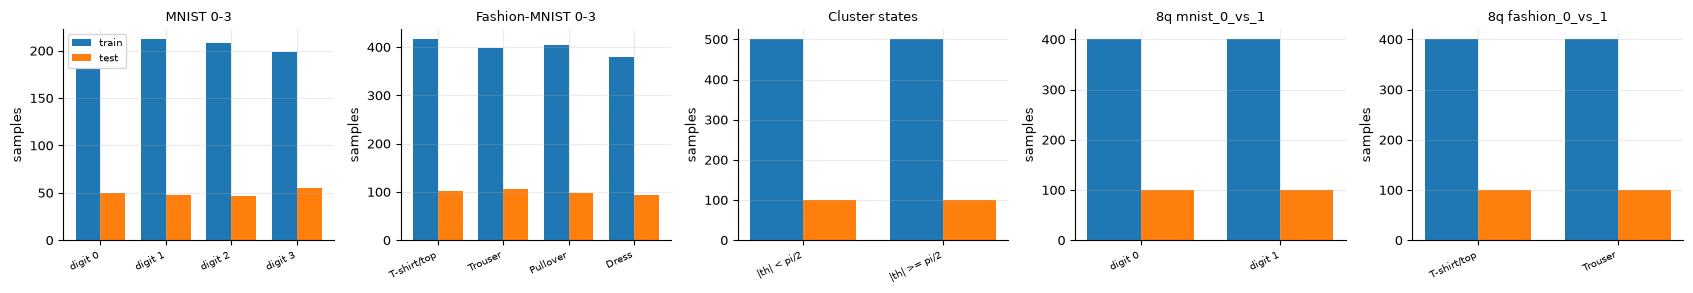

In [17]:
def describe(name, Xtr, ytr, Xte, yte, class_names, feature_desc, label_values):
    ytr_n, yte_n = np.asarray(ytr), np.asarray(yte)
    print(f"== {name}")
    print(f"   train {tuple(Xtr.shape)}  test {tuple(Xte.shape)}   feature names: {feature_desc}")
    print(f"   original label values {label_values} -> classes {class_names}")
    print(f"   train counts {np.bincount(ytr_n).tolist()}   test counts {np.bincount(yte_n).tolist()}")

pix = "pixel_r_c, r,c in 0..27 (784 intensities in [0,1]; amplitude-encoded into 10 qubits)"
describe("MNIST digits 0-3", *DATASETS["mnist"][0], *DATASETS["mnist"][1], CLASS_NAMES["mnist"], pix, CFG["mnist"]["data"]["classes"])
describe("Fashion-MNIST classes 0-3", *DATASETS["fashion_mnist"][0], *DATASETS["fashion_mnist"][1], CLASS_NAMES["fashion_mnist"], pix,
         CFG["fashion_mnist"]["data"]["classes"])
describe("Cluster-state excitation (generated)", *DATASETS["cluster"][0], *DATASETS["cluster"][1], CLASS_NAMES["cluster"],
         "complex amplitude <b|psi(theta)> of the 1024 basis states of 10 qubits (state-vector input)", [0, 1])
for t, d in TASK8.items():
    describe(f"hardware task {t}", d["z_train"], d["y_train"], d["z_test"], d["y_test"], IBM_NAMES[t],
             "PCA components pc_0..pc_7 of the 784 pixels (RX angles after normalisation)", [0, 1])

sets = [("MNIST 0-3", DATASETS["mnist"], CLASS_NAMES["mnist"]), ("Fashion-MNIST 0-3", DATASETS["fashion_mnist"], CLASS_NAMES["fashion_mnist"]),
        ("Cluster states", DATASETS["cluster"], CLASS_NAMES["cluster"])]
sets += [(f"8q {t}", [(None, d["y_train"]), (None, d["y_test"])], IBM_NAMES[t]) for t, d in TASK8.items()]
fig, axes = plt.subplots(1, len(sets), figsize=(3.4 * len(sets), 3.0))
for ax, (title, ((_, ytr), (_, yte)), names) in zip(axes, sets):
    k = len(names); w = 0.38; xs = np.arange(k)
    ax.bar(xs - w / 2, np.bincount(np.asarray(ytr), minlength=k), w, label="train")
    ax.bar(xs + w / 2, np.bincount(np.asarray(yte), minlength=k), w, label="test")
    ax.set_xticks(xs); ax.set_xticklabels([n.replace("|theta|", "|th|") for n in names], rotation=25, ha="right", fontsize=7)
    ax.set_title(title, fontsize=9); ax.set_ylabel("samples")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

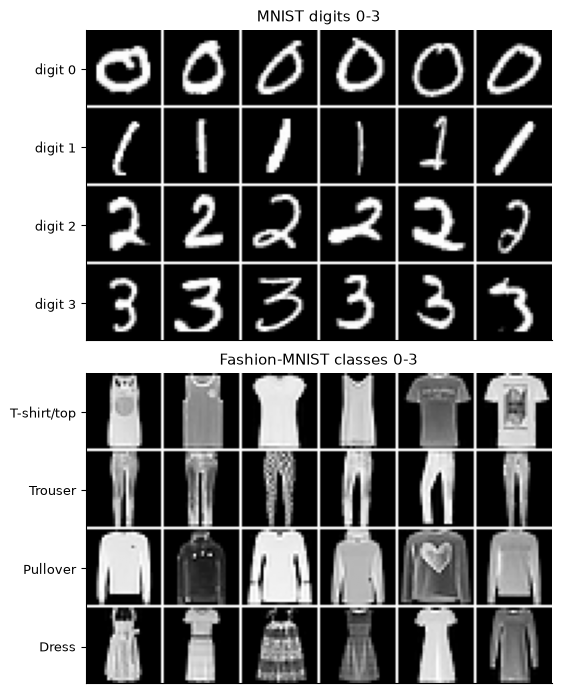

In [18]:
# Example images: six training samples per class (real observations, labelled)
fig, axes = plt.subplots(2, 1, figsize=(8.5, 7.0))
for ax, key, title in zip(axes, ("mnist", "fashion_mnist"), ("MNIST digits 0-3", "Fashion-MNIST classes 0-3")):
    X_, y_ = DATASETS[key][0]
    grid = np.ones((4 * 28 + 3, 6 * 28 + 5))
    for c in range(4):
        idx = np.where(y_.numpy() == c)[0][:6]
        for j, i in enumerate(idx):
            grid[c * 29:c * 29 + 28, j * 29:j * 29 + 28] = X_[i].view(28, 28).numpy()
    ax.imshow(grid, cmap="gray", vmin=0, vmax=1); ax.grid(False)
    ax.set_yticks([14 + 29 * c for c in range(4)]); ax.set_yticklabels(CLASS_NAMES[key]); ax.set_xticks([])
    ax.set_title(title)
plt.tight_layout(); plt.show()

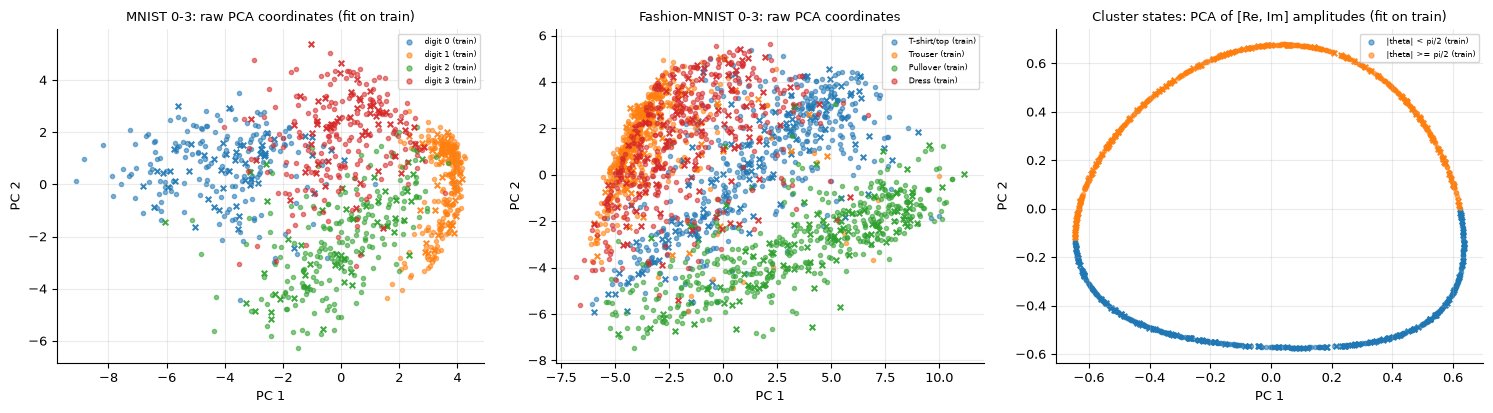

x = test samples (not used to fit the PCA); circles = training samples; colour = ground-truth class


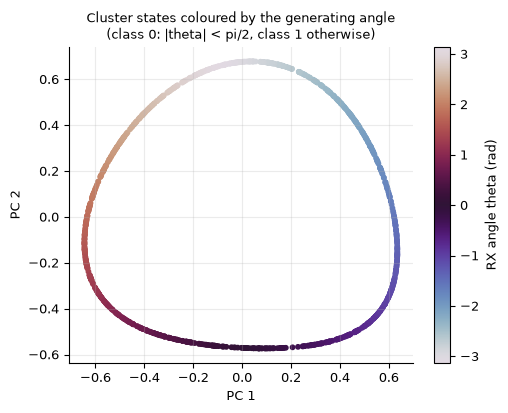

In [19]:
from sklearn.decomposition import PCA

def pca_scatter(ax, Xtr, ytr, Xte, yte, names, title, test_marker=True):
    pca = PCA(n_components=2, random_state=SEED).fit(Xtr)               # fitted on the training split only
    Ztr, Zte = pca.transform(Xtr), pca.transform(Xte)
    cmap = plt.get_cmap("tab10")
    for c, nm in enumerate(names):
        ax.scatter(*Ztr[np.asarray(ytr) == c].T, s=9, color=cmap(c), alpha=0.55, label=f"{nm} (train)")
        if test_marker:
            ax.scatter(*Zte[np.asarray(yte) == c].T, s=16, color=cmap(c), marker="x", alpha=0.9)
    ax.set_title(title, fontsize=9); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
    ax.legend(fontsize=6, markerscale=1.2)
    return pca, Ztr, Zte

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, key, title in zip(axes[:2], ("mnist", "fashion_mnist"), ("MNIST 0-3: raw PCA coordinates (fit on train)", "Fashion-MNIST 0-3: raw PCA coordinates")):
    (Xa, ya), (Xb, yb) = DATASETS[key]
    pca_scatter(ax, Xa.numpy(), ya.numpy(), Xb.numpy(), yb.numpy(), CLASS_NAMES[key], title)
(Xa, ya), (Xb, yb) = DATASETS["cluster"]
cplx = lambda X_: np.concatenate([X_.numpy().real, X_.numpy().imag], axis=1)
pca_c, Ztr_c, Zte_c = pca_scatter(axes[2], cplx(Xa), ya.numpy(), cplx(Xb), yb.numpy(), CLASS_NAMES["cluster"],
                                  "Cluster states: PCA of [Re, Im] amplitudes (fit on train)")
plt.tight_layout(); plt.show()
print("x = test samples (not used to fit the PCA); circles = training samples; colour = ground-truth class")

# the cluster labels come from the continuous excitation angle: colour the same coordinates by theta
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sc = ax.scatter(*Ztr_c.T, c=ANG_TR, cmap="twilight", s=10); plt.colorbar(sc, label="RX angle theta (rad)")
ax.set_title("Cluster states coloured by the generating angle\n(class 0: |theta| < pi/2, class 1 otherwise)", fontsize=9)
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.tight_layout(); plt.show()

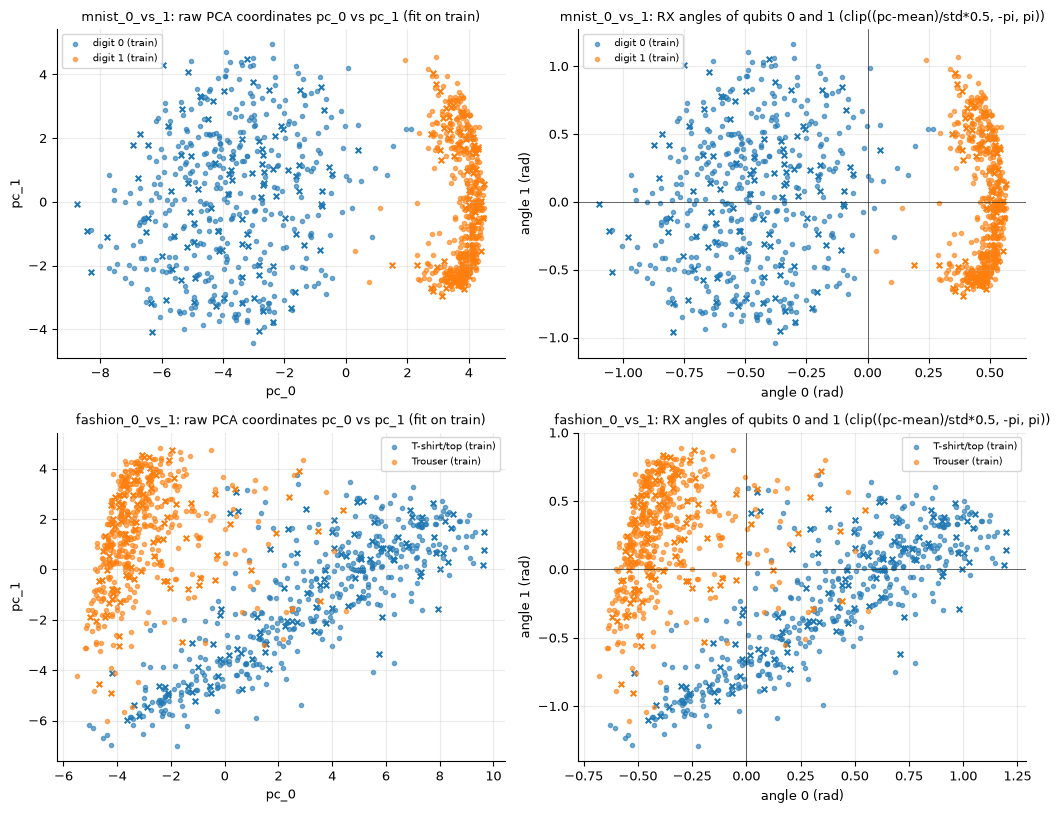

In [20]:
# Hardware tasks use ANGLE encoding: raw PCA coordinates first, then the angles that are actually fed to the RX gates.
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.2))
for r, (t, d) in enumerate(TASK8.items()):
    names, cmap = IBM_NAMES[t], plt.get_cmap("tab10")
    for c, nm in enumerate(names):
        axes[r, 0].scatter(d["z_train"][d["y_train"] == c, 0], d["z_train"][d["y_train"] == c, 1], s=9, color=cmap(c), alpha=0.6, label=f"{nm} (train)")
        axes[r, 0].scatter(d["z_test"][d["y_test"] == c, 0], d["z_test"][d["y_test"] == c, 1], s=16, marker="x", color=cmap(c))
        axes[r, 1].scatter(d["F_train"][d["y_train"] == c, 0], d["F_train"][d["y_train"] == c, 1], s=9, color=cmap(c), alpha=0.6, label=f"{nm} (train)")
        axes[r, 1].scatter(d["F_test"][d["y_test"] == c, 0], d["F_test"][d["y_test"] == c, 1], s=16, marker="x", color=cmap(c))
    axes[r, 0].set_title(f"{t}: raw PCA coordinates pc_0 vs pc_1 (fit on train)", fontsize=9)
    axes[r, 1].set_title(f"{t}: RX angles of qubits 0 and 1 (clip((pc-mean)/std*0.5, -pi, pi))", fontsize=9)
    axes[r, 1].axhline(0, color="k", lw=0.4); axes[r, 1].axvline(0, color="k", lw=0.4)
    for a in axes[r]:
        a.legend(fontsize=7)
    axes[r, 0].set_xlabel("pc_0"); axes[r, 0].set_ylabel("pc_1"); axes[r, 1].set_xlabel("angle 0 (rad)"); axes[r, 1].set_ylabel("angle 1 (rad)")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Below is the circuit that is **actually executed**, drawn from the executed object, together with qubit count, depth and trainable-parameter count. The 10-qubit and 8-qubit models run as PennyLane QNodes on `default.qubit`; we draw the QNode after decomposing `StronglyEntanglingLayers` into its `Rot` and `CNOT` gates (the encoder, a single state-preparation box, is kept as is). Each layer applies one `Rot(phi, theta, omega)` to every qubit and then a ring of `CNOT(i, (i + r) mod n)` with range `r = layer mod (n - 1) + 1`. The measurement is the computational-basis probability of the first qubits, to which the POVM of the paper is applied by classical post-processing of the reduced state (`E_k (x) I`). Circuit details the paper omits (encoder, layer ranges, readout wires) are taken from the public artifact. One drawing per distinct architecture follows: MNIST (also used by the diagnostic model and by our retrained models), Fashion-MNIST, cluster, the 8-qubit hardware QNN (PennyLane and the Qiskit circuit that was sent to the device), and the 30-qubit Qiskit circuit.

MNIST / diagnostic / retrained: 10 qubits, amplitude encoding, 4 strongly-entangling layers, 2 readout qubits
   qubits = 10, readout qubits = 2, depth = 26, trainable parameters = 120 (4 layers x 10 qubits x 3 angles), gates = {'AmplitudeEmbedding': 1, 'Rot': 40, 'CNOT': 40}


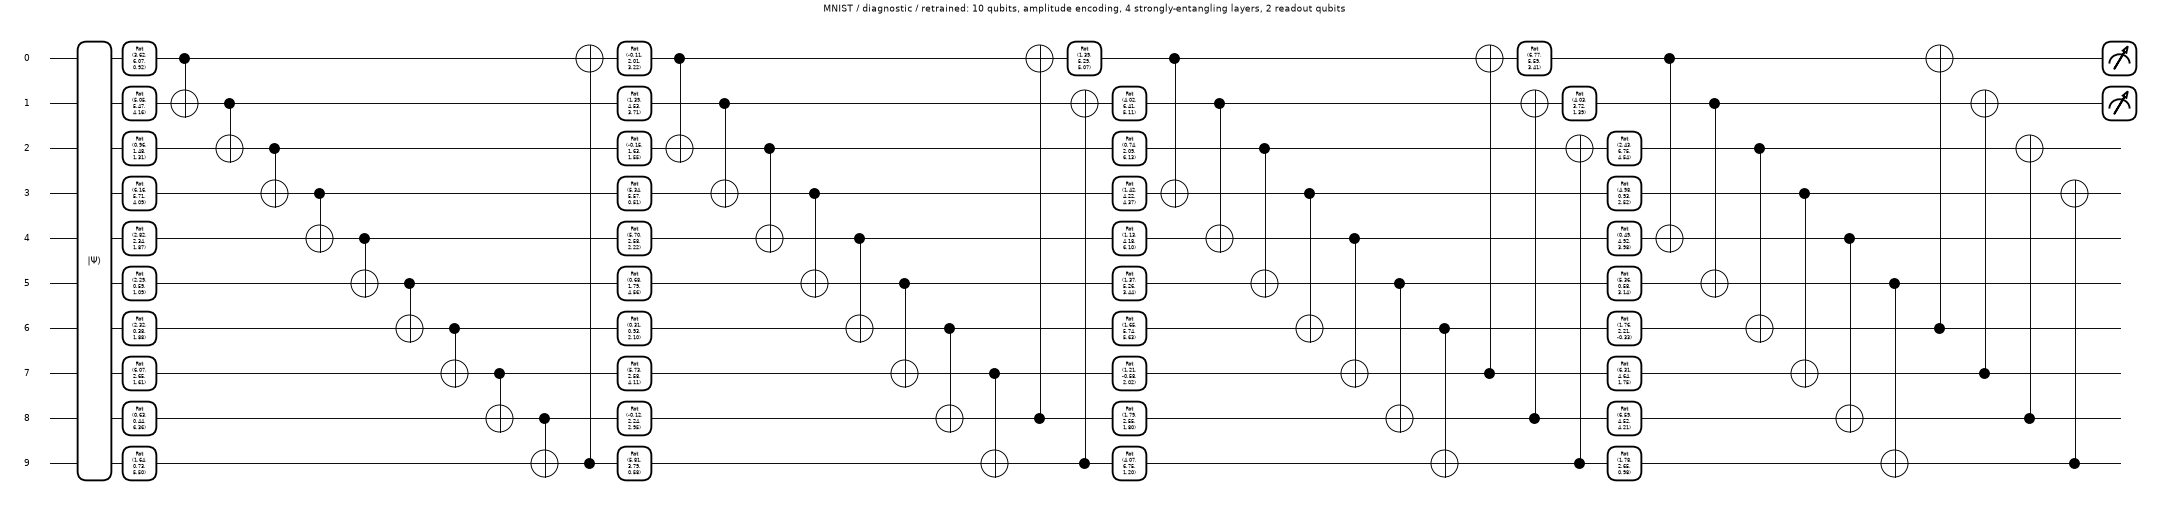

Fashion-MNIST: 10 qubits, amplitude encoding, 6 layers, 2 readout qubits
   qubits = 10, readout qubits = 2, depth = 33, trainable parameters = 180 (6 layers x 10 qubits x 3 angles), gates = {'AmplitudeEmbedding': 1, 'Rot': 60, 'CNOT': 60}


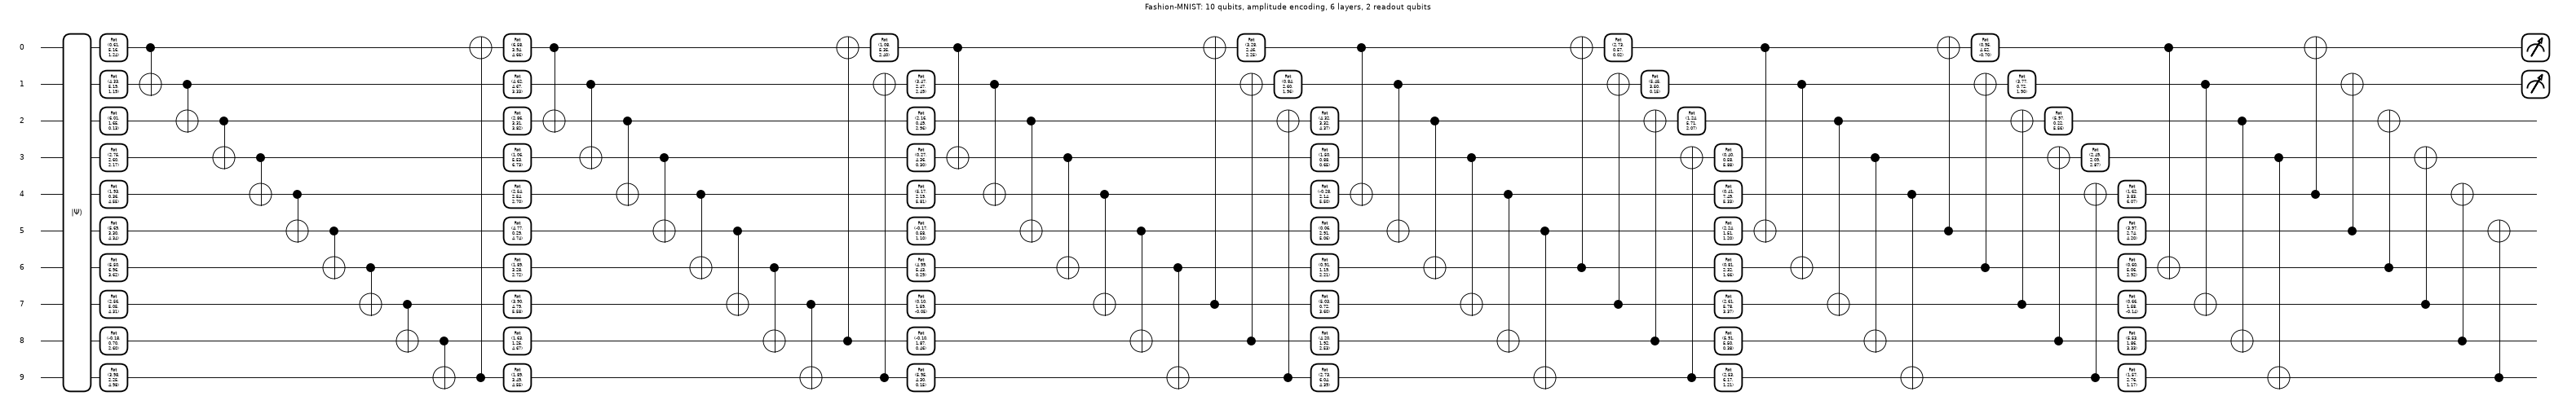

Cluster excitation: 10 qubits, state-vector input, 8 layers, 1 readout qubit
   qubits = 10, readout qubits = 1, depth = 43, trainable parameters = 240 (8 layers x 10 qubits x 3 angles), gates = {'StatePrep': 1, 'Rot': 80, 'CNOT': 80}


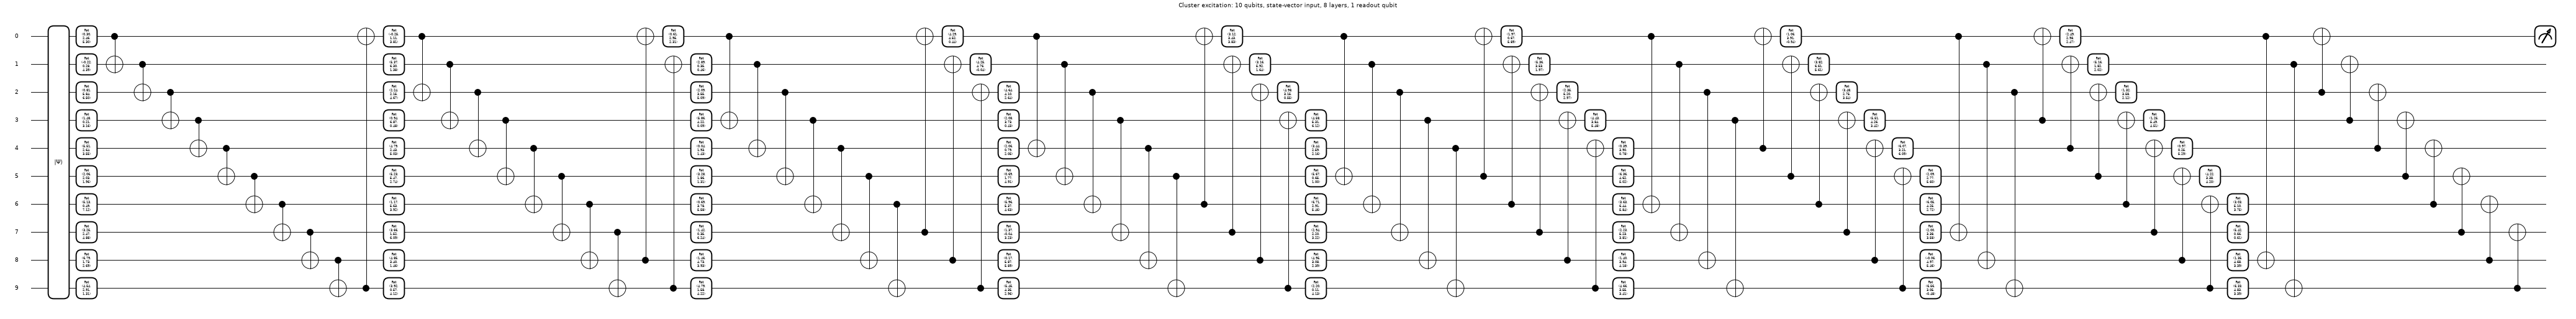

Hardware QNN (MNIST 0 vs 1): 8 qubits, RX angle encoding, 3 layers, 1 readout qubit
   qubits = 8, readout qubits = 1, depth = 19, trainable parameters = 72 (3 layers x 8 qubits x 3 angles), gates = {'RX': 8, 'Rot': 24, 'CNOT': 24}


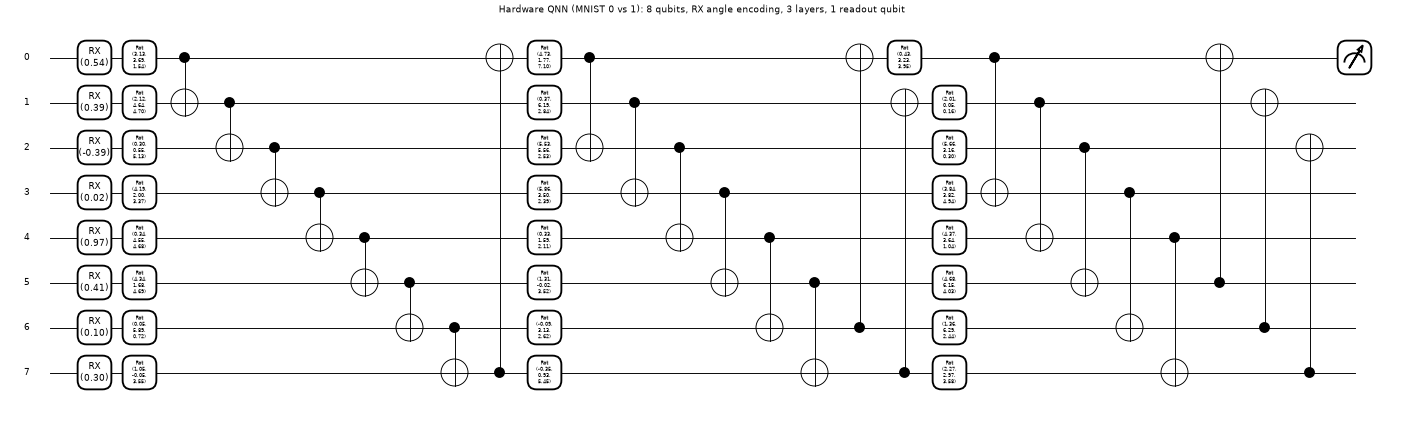

In [21]:
ARCH = {
    "MNIST / diagnostic / retrained: 10 qubits, amplitude encoding, 4 strongly-entangling layers, 2 readout qubits":
        dict(qnn=QNN(10, 4, 2, "amplitude"), W=lambda: torch.tensor(load_weights_file(REPO / CFG["mnist"]["frozen_weights_path"])),
             x=lambda: DATASETS["mnist"][1][0][0], gates={qml.AmplitudeEmbedding, qml.Rot, qml.CNOT}),
    "Fashion-MNIST: 10 qubits, amplitude encoding, 6 layers, 2 readout qubits":
        dict(qnn=QNN(10, 6, 2, "amplitude"), W=lambda: torch.tensor(load_weights_file(REPO / CFG["fashion_mnist"]["frozen_weights_path"])),
             x=lambda: DATASETS["fashion_mnist"][1][0][0], gates={qml.AmplitudeEmbedding, qml.Rot, qml.CNOT}),
    "Cluster excitation: 10 qubits, state-vector input, 8 layers, 1 readout qubit":
        dict(qnn=QNN(10, 8, 1, "state_vector"), W=lambda: torch.tensor(load_weights_file(REPO / CFG["cluster"]["frozen_weights_path"])),
             x=lambda: DATASETS["cluster"][1][0][0], gates={qml.StatePrep, qml.Rot, qml.CNOT}),
    "Hardware QNN (MNIST 0 vs 1): 8 qubits, RX angle encoding, 3 layers, 1 readout qubit":
        dict(qnn=QNN(8, 3, 1, "angle"), W=lambda: torch.tensor(TASK8["mnist_0_vs_1"]["weights"]),
             x=lambda: torch.tensor(TASK8["mnist_0_vs_1"]["F_test"][0], dtype=torch.float32), gates={qml.RX, qml.Rot, qml.CNOT}),
}
for title, spec in ARCH.items():
    qnn_, W_, x_ = spec["qnn"], spec["W"](), spec["x"]()
    dq = qml.transforms.decompose(qnn_.probs_qnode, gate_set=spec["gates"])
    res = qml.specs(dq)(W_, x_).resources
    ops = dict(res.gate_types)
    print(f"{title}\n   qubits = {qnn_.n}, readout qubits = {qnn_.n_out}, depth = {res.depth}, "
          f"trainable parameters = {W_.numel()} ({qnn_.L} layers x {qnn_.n} qubits x 3 angles), gates = {ops}")
    fig, ax = qml.draw_mpl(dq, decimals=2)(W_, x_)
    fig.suptitle(title, fontsize=14, y=1.02); fig.set_dpi(45)
    plt.show()

### Qiskit re-expression and equivalence checks

The paper cites Qiskit and TensorFlow Quantum, so we re-express the executed circuits in Qiskit and **assert that they are the same unitary evolution**: for the three 10-qubit models we rebuild `StronglyEntanglingLayers` gate by gate (`Rot = RZ(omega) RY(theta) RZ(phi)`, ring `CX` with the layer-dependent range), apply it to the same input state with `qiskit.quantum_info.Statevector` and compare with PennyLane's output state (qubit order reversed, because PennyLane wire 0 is the most significant bit and Qiskit qubit 0 the least significant). For the hardware QNNs, the authors archived the 40 logical Qiskit circuits that were transpiled and sent to `ibm_kingston` (`logical_circuits.qpy`); we load them, simulate them exactly and compare their readout probabilities with our PennyLane model on the same stored features.

                         model  state_fidelity  qiskit_depth                      qiskit_ops
MNIST / diagnostic / retrained             1.0            33  {'rz': 80, 'ry': 40, 'cx': 40}
                 Fashion-MNIST             1.0            44 {'rz': 120, 'ry': 60, 'cx': 60}
            Cluster excitation             1.0            58 {'rz': 160, 'ry': 80, 'cx': 80}


40 archived hardware circuits vs PennyLane model: max |p_qiskit - p_pennylane| = 4.60e-07
hardware circuit 'mnist_0_vs_1_18_rep00': qubits = 8, depth = 25, gates = {'rz': 48, 'ry': 24, 'cx': 24, 'rx': 8, 'measure': 1}, trainable parameters = 3 x 8 x 3 = 72 (bound to numbers)


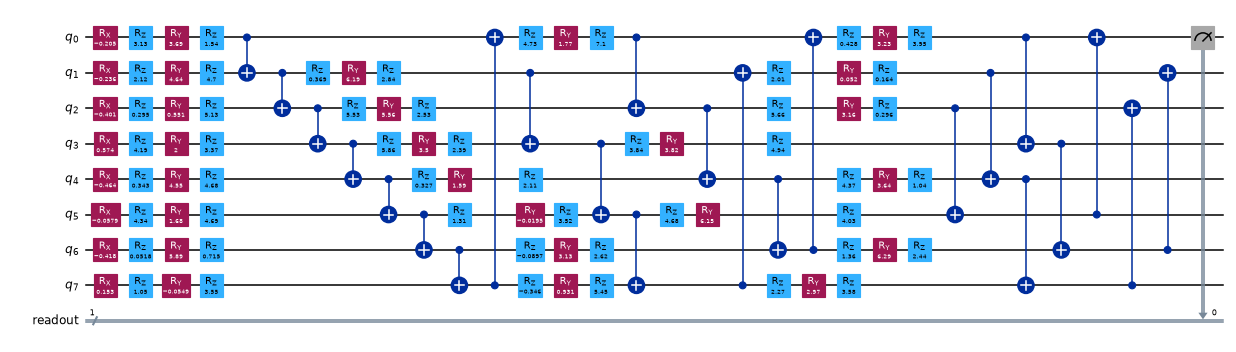

In [22]:
def sel_qiskit_circuit(W):
    """Qiskit version of qml.StronglyEntanglingLayers(W) (W: layers x qubits x 3)."""
    L, n, _ = W.shape
    qc = QuantumCircuit(n)
    for l in range(L):
        for i in range(n):
            phi, theta, omega = (float(v) for v in W[l, i])
            qc.rz(phi, i); qc.ry(theta, i); qc.rz(omega, i)            # qml.Rot(phi, theta, omega)
        r = l % (n - 1) + 1
        for i in range(n):
            qc.cx(i, (i + r) % n)
    return qc

def qiskit_output_state(W, psi_in):
    sv = Statevector(np.asarray(psi_in, dtype=complex)).reverse_qargs().evolve(sel_qiskit_circuit(np.asarray(W)))
    return sv.reverse_qargs().data

equiv = []
for title, spec in list(ARCH.items())[:3]:
    qnn_, W_, x_ = spec["qnn"], spec["W"](), spec["x"]()
    with torch.no_grad():
        psi_pl = qnn_.state_qnode(W_, x_).numpy().astype(complex)
        psi_in = qnn_.input_qnode(x_).numpy().astype(complex)
    psi_qk = qiskit_output_state(W_.numpy(), psi_in)
    fid = abs(np.vdot(psi_pl / np.linalg.norm(psi_pl), psi_qk / np.linalg.norm(psi_qk))) ** 2
    qc_ = sel_qiskit_circuit(W_.numpy())
    equiv.append(dict(model=title.split(":")[0], state_fidelity=fid, qiskit_depth=qc_.depth(), qiskit_ops=dict(qc_.count_ops())))
    assert fid > 1 - 1e-5, f"Qiskit and PennyLane circuits differ for {title}"
print(pd.DataFrame(equiv).to_string(index=False))

# the archived hardware circuits (logical level) versus our PennyLane model on the stored features
with open(IBM / "logical_circuits.qpy", "rb") as fh:
    HW_CIRCUITS = qpy.load(fh)
worst = 0.0
for qc_ in HW_CIRCUITS:
    task, sid = qc_.name.rsplit("_", 2)[0], int(qc_.name.split("_")[-2])
    sel = np.load(IBM / task / "selected_samples.npz", allow_pickle=True)
    j = int(np.where(sel["sample_id"] == sid)[0][0])
    sv_probs = Statevector.from_instruction(qc_.remove_final_measurements(inplace=False)).probabilities([0])
    q8 = QNN(8, 3, 1, "angle")
    with torch.no_grad():
        pl_probs = q8.probs_qnode(torch.tensor(TASK8[task]["weights"]), torch.tensor(sel["x_features"][j], dtype=torch.float32)).numpy()
    worst = max(worst, float(np.abs(sv_probs - pl_probs).max()))
print(f"40 archived hardware circuits vs PennyLane model: max |p_qiskit - p_pennylane| = {worst:.2e}")
assert worst < 1e-5
c0 = HW_CIRCUITS[0]
print(f"hardware circuit '{c0.name}': qubits = {c0.num_qubits}, depth = {c0.depth()}, gates = {dict(c0.count_ops())}, trainable parameters = 3 x 8 x 3 = 72 (bound to numbers)")
display(c0.draw("mpl", fold=-1, scale=0.55))

30-qubit stress circuit (the object simulated by Aer MPS): qubits = 30, depth = 22, trainable (random, untrained) rotation angles = 360, input angles = 30, two-qubit gates = 116, measured qubits = 2, gates = {'rz': 240, 'ry': 150, 'cx': 116, 'measure': 2}


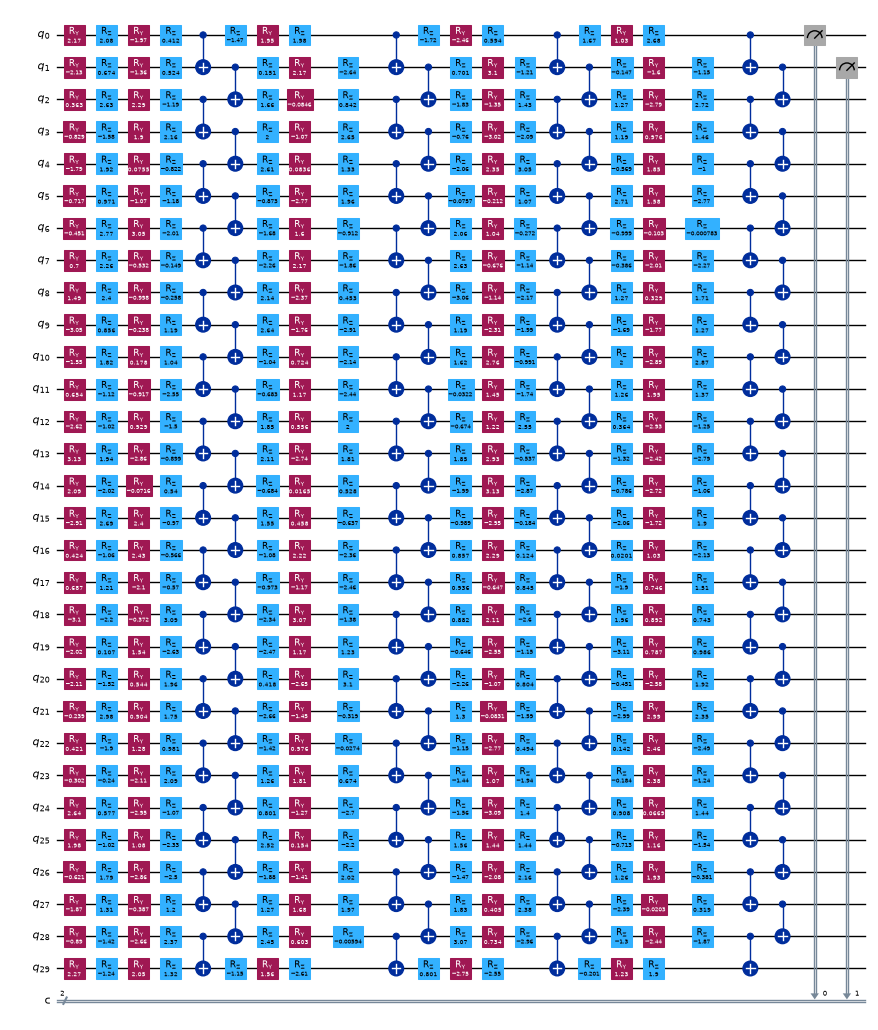

In [23]:
def build_stress_circuit(x, w, n_qubits, n_out):
    """The 30-qubit circuit of the artifact: RY(x_i) inputs, L x [Rz Ry Rz + brick-wall CX], measure the first qubits."""
    qc = QuantumCircuit(n_qubits, n_out)
    for i, a_ in enumerate(np.asarray(x, float)):
        qc.ry(float(a_), i)
    for l in range(w.shape[0]):
        for i in range(n_qubits):
            qc.rz(float(w[l, i, 0]), i); qc.ry(float(w[l, i, 1]), i); qc.rz(float(w[l, i, 2]), i)
        for i in range(0, n_qubits - 1, 2):
            qc.cx(i, i + 1)
        for i in range(1, n_qubits - 1, 2):
            qc.cx(i, i + 1)
    for i in range(n_out):
        qc.measure(i, i)
    return qc

st_cfg = yaml.safe_load((REPO / "configs" / "stress_30q.yaml").read_text())
st_rng = np.random.default_rng(st_cfg["seed"])
N_ST, L_ST, Q_ST = st_cfg["analysis"]["samples"], st_cfg["model"]["n_layers"], st_cfg["model"]["n_qubits"]
ST_INPUTS = st_rng.uniform(-np.pi, np.pi, size=(N_ST, Q_ST))
ST_WEIGHTS = st_rng.uniform(-np.pi, np.pi, size=(L_ST, Q_ST, 3))
saved = np.load(REPO / "results" / "stress_30q" / "stress_qnn_inputs_weights.npz")
assert np.allclose(saved["inputs"], ST_INPUTS) and np.allclose(saved["weights"], ST_WEIGHTS), "stress inputs differ from the artifact"
st_qc = build_stress_circuit(ST_INPUTS[0], ST_WEIGHTS, Q_ST, 2)
ops = dict(st_qc.count_ops())
print(f"30-qubit stress circuit (the object simulated by Aer MPS): qubits = {st_qc.num_qubits}, depth = {st_qc.depth()}, "
      f"trainable (random, untrained) rotation angles = {ST_WEIGHTS.size}, input angles = {Q_ST}, "
      f"two-qubit gates = {ops.get('cx', 0)}, measured qubits = 2, gates = {ops}")
display(st_qc.draw("mpl", fold=45, scale=0.5))

## The certification pipeline for one model

`certify_model` reproduces the evaluation protocol of Section 6 for any trained classifier and any readout:

1. compute the readout probabilities `p_k = Tr[E_k rho_out]` of every test input and the accuracy;
2. walk through the correctly classified test inputs in the seeded random order (`SAMPLE_SEED`), compute the certified lower bound (Algorithm 2), the numerical white-box reference and the kernel upper bound (Algorithm 1);
3. keep the first 20 inputs for which both the lower bound and the reference are at least `5e-4` and record every exclusion (an input whose lower bound exceeds the reference by more than `1e-8` outside the near-zero floor aborts the run, because that would contradict the theory);
4. run random search, FGSM and PGD on the retained inputs;
5. attach 95% finite-shot intervals (4096 shots, parametric replicas).

In [24]:
def certify_model(tag, qnn, W, X, y, effects, quantum, n_attack=None, n_retain=N_RETAIN, verbose=True):
    n_attack = N_ATTACK if n_attack is None else n_attack
    effects = [np.asarray(E, dtype=complex) for E in effects]
    E_arr = np.array(effects)
    Et = torch.tensor(E_arr, dtype=torch.complex64)
    a, b = spectral_box(effects)
    t0 = time.time()
    with torch.no_grad():
        rho_all = to_np_c(qnn.rho_out(W, X))
    rho_all /= np.trace(rho_all, axis1=1, axis2=2).real[:, None, None]
    P = np.real(np.einsum("kab,nba->nk", E_arr, rho_all)); P /= P.sum(1, keepdims=True)
    y_np = y.numpy()
    acc = float((P.argmax(1) == y_np).mean())
    order = [int(i) for i in np.random.default_rng(SAMPLE_SEED).permutation(len(X)) if P[i].argmax() == y_np[i]]
    rows, rejected = [], []
    for rank, i in enumerate(order, 1):
        rho, p = rho_all[i], P[i]
        t = int(p.argmax())
        low, prior = certified_lower_bound(p, t, a, b), prior_lower_bound(p, t)
        ref = numerical_reference(rho, effects, t)
        reason = None
        if low > ref + 1e-8:
            if not (abs(low) <= REPORT_FLOOR and abs(ref) <= REPORT_FLOOR):
                raise RuntimeError(f"lower bound {low:.3e} exceeds the reference {ref:.3e}: theory violated")
            reason = "near-zero lower above reference"
        elif low < REPORT_FLOOR:
            reason = "lower below reporting floor"
        elif ref < REPORT_FLOOR:
            reason = "reference below reporting floor"
        if reason:
            rejected.append(dict(candidate_rank=rank, sample_idx=i, reason=reason, lower=low, reference=ref))
            continue
        sp = upper_projectors(effects, t)
        ov = {k: float(np.real(np.trace(Pk @ rho))) for k, (s, Pk) in sp.items()}
        up, comp = upper_bound_from_overlaps(sp, ov)
        best_ov = max([ov[k] for k, (s, _) in sp.items() if s == "finite"], default=float("nan"))
        rows.append(dict(sample_idx=i, candidate_rank=rank, true_label=int(y_np[i]), pred_label=t, p=p.tolist(),
                         prior_lower=prior, lower=low, reference=ref, upper=up, upper_competitor=comp, kernel_overlap=best_ov))
        if len(rows) == n_retain:
            break
    if len(rows) < n_retain:
        print(f"  WARNING [{tag}]: only {len(rows)} of {n_retain} inputs passed the reporting rule")
    df = pd.DataFrame(rows)
    df.insert(0, "plot_index", np.arange(1, len(df) + 1))
    # empirical attacks (gradient access, stronger than KRQA) on the first n_attack retained inputs
    for m in ("random", "fgsm", "pgd"):
        df[f"{m}_upper"], df[f"{m}_success"] = np.nan, np.nan
    for j in range(min(n_attack, len(df))):
        i = int(df.sample_idx[j])
        ub, succ = attack_suite(qnn, W, Et, X[i], int(y_np[i]), ATTACK_EPS, quantum, seed=SEED + i)
        for m in ub:
            df.loc[j, f"{m}_upper"], df.loc[j, f"{m}_success"] = ub[m], float(succ[m])
    # finite-shot 95% intervals (Section 6): point values stay ideal-probability values
    for col in ("prior_lower", "lower", "upper"):
        df[f"{col}_lo"], df[f"{col}_hi"] = np.nan, np.nan
    for j, r in df.iterrows():
        p, t = np.array(r.p), int(r.pred_label)
        lo_, hi_ = multinomial_interval(p, lambda q: prior_lower_bound(q, t), SHOTS, N_REPLICAS, seed=SEED + 17 * j + 1)
        df.loc[j, ["prior_lower_lo", "prior_lower_hi"]] = lo_, hi_
        if abs(r.lower - r.prior_lower) <= 1e-10:
            df.loc[j, ["lower_lo", "lower_hi"]] = lo_, hi_
        else:
            lo2, hi2 = multinomial_interval(p, lambda q: certified_lower_bound(q, t, a, b), SHOTS, N_REPLICAS, seed=SEED + 17 * j + 2)
            df.loc[j, ["lower_lo", "lower_hi"]] = lo2, hi2
        lo3, hi3 = binomial_upper_interval(r.kernel_overlap, SHOTS, N_REPLICAS, seed=SEED + 17 * j + 3)
        df.loc[j, ["upper_lo", "upper_hi"]] = lo3, hi3
    attacked = df.dropna(subset=["fgsm_success"])
    summ = dict(tag=tag, accuracy=acc, traversed=int(df.candidate_rank.max()) if len(df) else 0, retained=len(df), rejected=len(rejected),
                lower_mean=df.lower.mean(), prior_mean=df.prior_lower.mean(), reference_mean=df.reference.mean(), upper_mean=df.upper.mean(),
                strict_improvements=int((df.lower > df.prior_lower + 1e-9).sum()),
                equal_to_prior_all=bool(((df.lower - df.prior_lower).abs() <= 1e-9).all()),
                ordered=bool(((df.lower <= df.reference + 1e-7) & (df.reference <= df.upper + 1e-7)).all()),
                upper_nontrivial=int((df.upper < 1 - 1e-8).sum()),
                n_attacked=len(attacked),
                random_rate=float(attacked.random_success.mean()) if len(attacked) else np.nan,
                fgsm_rate=float(attacked.fgsm_success.mean()) if len(attacked) else np.nan,
                pgd_rate=float(attacked.pgd_success.mean()) if len(attacked) else np.nan,
                attack_failed_kernel_nontrivial=int(((attacked.fgsm_success == 0) & (attacked.pgd_success == 0) & (attacked.random_success == 0) & (attacked.upper < 1 - 1e-8)).sum()) if len(attacked) else 0,
                seconds=time.time() - t0)
    if verbose:
        print(f"[{tag}] accuracy {acc:.4f} | retained {len(df)} of {summ['traversed']} traversed ({len(rejected)} rejected) | "
              f"mean lower {summ['lower_mean']:.4e} (prior-only {summ['prior_mean']:.4e}) | mean reference {summ['reference_mean']:.4e} | "
              f"mean upper {summ['upper_mean']:.4f} | ordered {summ['ordered']} | {summ['seconds']:.0f}s")
        if len(attacked):
            print(f"      attack success on {len(attacked)} inputs: random {summ['random_rate']:.0%}  FGSM {summ['fgsm_rate']:.0%}  PGD {summ['pgd_rate']:.0%}")
    return dict(df=df, rejected=pd.DataFrame(rejected), summary=summ, a=a, b=b, effects=effects)

def frozen_setup(name):
    cfg = CFG[name]; m = cfg["model"]; fm = cfg["fixed_measurement"]
    qnn = QNN(m["n_qubits"], m["n_layers"], m["output_qubits"], m["encoder_type"])
    W = torch.tensor(load_weights_file(REPO / cfg["frozen_weights_path"]))
    nC = 2 ** m["output_qubits"]
    if fm["family"] == "randomized_basis":
        effects = randomized_basis_povm(nC, fm.get("n_bases", 3), fm["strength"], fm["seed"])
    elif fm["family"] == "amplified_four_class_diagonal":
        effects = amplified_diagonal_povm()
    else:
        raise ValueError(fm["family"])
    saved_effects = np.load(REPO / fm["artifact"], allow_pickle=False)["effects"]
    assert np.allclose(np.array(effects), saved_effects, atol=1e-12), "rebuilt POVM differs from the artifact's saved POVM"
    assert validate_povm(effects)["valid"]
    return qnn, W, effects

def compare_with_artifact(name, res):
    ref_df = pd.read_csv(REPO / "results" / name / "robustness_results.csv")
    sel = pd.read_csv(REPO / "results" / name / "selected_sample_indices.csv")
    df = res["df"]
    same = list(df.sample_idx) == list(sel.sample_idx)
    m = df.merge(ref_df, on="sample_idx", suffixes=("", "_a"))
    out = dict(task=name, same_retained_indices=same,
               max_diff_lower=float((m.lower - m.dist_lower).abs().max()), max_diff_reference=float((m.reference - m.reference_estimate).abs().max()),
               max_diff_upper=float((m.upper - m.kernel_upper).abs().max()))
    if df.fgsm_success.notna().all():
        out["fgsm_outcome_agreement"] = f"{int((m.fgsm_success.astype(bool) == m.fgsm_attack_success.astype(bool)).sum())}/{len(m)}"
        out["pgd_outcome_agreement"] = f"{int((m.pgd_success.astype(bool) == m.pgd_attack_success.astype(bool)).sum())}/{len(m)}"
    return out

## KRQA in action: certifying a black box from shots

Before the full experiments, here is the access model of the paper made explicit. `KRQAService` hides the weights, the circuit and the state; the only method the auditor may call is `run(x, readout, shots)`, which returns **counts** for a readout the auditor specifies (the published effects, or a binary projector pair derived from them). `certify_krqa` then computes `eps_RLB` from the native-readout counts and `eps_RUB` from one binary-readout run per competitor, i.e. exactly Algorithms 1 and 2 with finite-shot estimates. We compare with the ideal-probability values on the authors' frozen MNIST model. The number of shots needed for a probability error `eps` with confidence `1 - delta` over `C` classes is `N = ln(2C/delta) / (2 eps^2)` (Theorem 4.8, Hoeffding plus a union bound).

In [25]:
class KRQAService:
    """A remote quantum classifier seen through known-readout query access (KRQA)."""
    def __init__(self, qnn, W, seed):
        self._qnn, self._W, self._rng = qnn, W, np.random.default_rng(seed)     # private: never read by the auditor
        self.total_shots = 0
    def run(self, x, readout, shots):
        with torch.no_grad():
            rho = to_np_c(self._qnn.rho_out(self._W, x[None]))[0]
        p = np.clip(np.array([np.real(np.trace(E @ rho)) for E in readout]), 0, None)
        self.total_shots += shots
        return self._rng.multinomial(shots, p / p.sum())

def certify_krqa(service, x, published_effects, shots):
    """Auditor side: uses only the published readout, the input and the service's counts."""
    eff = [np.asarray(E, complex) for E in published_effects]
    p_hat = service.run(x, eff, shots) / shots
    t = int(p_hat.argmax())
    a, b = spectral_box(eff)
    lower = certified_lower_bound(p_hat, t, a, b)
    proj, overlaps = upper_projectors(eff, t), {}
    for k, (status, Pk) in proj.items():
        if status == "finite":
            overlaps[k] = service.run(x, [Pk, np.eye(len(Pk)) - Pk], shots)[0] / shots     # binary readout {P_k, I - P_k}
        else:
            overlaps[k] = 0.0
    upper, _ = upper_bound_from_overlaps(proj, overlaps)
    return dict(pred=t, lower=lower, upper=upper)

eps_acc, delta, C_ = 0.01, 0.05, 4
print(f"shots per probability for error <= {eps_acc} with confidence {1 - delta:.0%} over {C_} classes: "
      f"{math.ceil(math.log(2 * C_ / delta) / (2 * eps_acc ** 2)):,}   (we use {SHOTS} per readout, so expect errors of a few 1e-2 in the upper bound)")

shots per probability for error <= 0.01 with confidence 95% over 4 classes: 25,376   (we use 4096 per readout, so expect errors of a few 1e-2 in the upper bound)


## MNIST: frozen weights of the authors (10 qubits, 4 layers, accuracy 91.5% claimed)

We load the authors' frozen checkpoint, rebuild the randomized-basis POVM (strength 0.05, seed 4) from its generator and run the full pipeline.

In [26]:
RES = {}
qnn_m, W_m, E_m = frozen_setup("mnist")
(Xtr_m, ytr_m), (Xte_m, yte_m) = DATASETS["mnist"]
RES["mnist"] = certify_model("MNIST, frozen weights", qnn_m, W_m, Xte_m, yte_m, E_m, quantum=False)
print(pd.DataFrame([compare_with_artifact("mnist", RES["mnist"])]).to_string(index=False))
RES["mnist"]["df"][["plot_index", "sample_idx", "true_label", "lower", "prior_lower", "reference", "upper", "random_upper", "fgsm_upper", "pgd_upper"]].head(6).round(5)

[MNIST, frozen weights] accuracy 0.9150 | retained 20 of 31 traversed (11 rejected) | mean lower 1.1583e-03 (prior-only 1.1583e-03) | mean reference 1.2838e-03 | mean upper 0.3166 | ordered True | 134s
      attack success on 20 inputs: random 0%  FGSM 75%  PGD 75%
 task  same_retained_indices  max_diff_lower  max_diff_reference  max_diff_upper fgsm_outcome_agreement pgd_outcome_agreement
mnist                   True    1.976595e-09        1.340112e-07    9.318238e-08                  20/20                 19/20


,plot_index,sample_idx,true_label,lower,prior_lower,reference,upper,random_upper,fgsm_upper,pgd_upper
0,1,181,3,0.00111,0.00111,0.00124,0.31915,1.0,0.00955,0.00948
1,2,166,3,0.00107,0.00107,0.00117,0.31812,1.0,0.01149,0.01141
2,3,171,0,0.00096,0.00096,0.00106,0.31989,1.0,0.00978,0.00956
3,4,120,1,0.00140,0.00140,0.00159,0.30471,1.0,0.01552,0.01515
4,5,184,1,0.00196,0.00196,0.00223,0.31987,1.0,0.02947,0.02918
5,6,52,3,0.00064,0.00064,0.00071,0.31102,1.0,0.00974,0.00963


In [27]:
# KRQA black-box demonstration on the first retained MNIST inputs
service = KRQAService(qnn_m, W_m, seed=SEED)
rows_ = []
for j in range(N_KRQA_DEMO):
    r = RES["mnist"]["df"].iloc[j]
    est = certify_krqa(service, Xte_m[int(r.sample_idx)], E_m, SHOTS)
    rows_.append(dict(sample=int(r.sample_idx), label_ok=est["pred"] == int(r.pred_label), lower_shots=est["lower"], lower_ideal=r.lower,
                      upper_shots=est["upper"], upper_ideal=r.upper, abs_err_upper=abs(est["upper"] - r.upper)))
kd = pd.DataFrame(rows_)
print(kd.round(5).to_string(index=False))
print(f"total shots used by the auditor: {service.total_shots:,} ({service.total_shots // N_KRQA_DEMO:,} per input); "
      f"mean |upper(shots) - upper(ideal)| = {kd.abs_err_upper.mean():.4f}")
assert (kd.upper_shots >= kd.lower_shots).all()

 sample  label_ok  lower_shots  lower_ideal  upper_shots  upper_ideal  abs_err_upper
    181      True      0.00129      0.00111      0.31856      0.31915        0.00059
    166      True      0.00118      0.00107      0.32036      0.31812        0.00224
    171      True      0.00065      0.00096      0.31588      0.31989        0.00401
    120      True      0.00155      0.00140      0.29966      0.30471        0.00505
    184      True      0.00216      0.00196      0.31892      0.31987        0.00094
     52      True      0.00055      0.00064      0.31463      0.31102        0.00362
    179      True      0.00126      0.00161      0.29983      0.30456        0.00473
     53      True      0.00029      0.00069      0.32054      0.31801        0.00253
total shots used by the auditor: 131,072 (16,384 per input); mean |upper(shots) - upper(ideal)| = 0.0030


## Fashion-MNIST, cluster excitation and the lower-bound diagnostic (frozen weights)

The same pipeline on the other three frozen models. The diagnostic model is a separate, class-3-focused MNIST classifier with an amplified diagonal readout whose spectral box is active (its accuracy of 27.5% is irrelevant to what it demonstrates).

In [28]:
qnn_f, W_f, E_f = frozen_setup("fashion_mnist")
(Xtr_f, ytr_f), (Xte_f, yte_f) = DATASETS["fashion_mnist"]
RES["fashion_mnist"] = certify_model("Fashion-MNIST, frozen weights", qnn_f, W_f, Xte_f, yte_f, E_f, quantum=False)
print(pd.DataFrame([compare_with_artifact("fashion_mnist", RES["fashion_mnist"])]).to_string(index=False))

[Fashion-MNIST, frozen weights] accuracy 0.8525 | retained 20 of 35 traversed (15 rejected) | mean lower 1.2822e-03 (prior-only 1.2822e-03) | mean reference 1.5244e-03 | mean upper 0.3019 | ordered True | 310s
      attack success on 20 inputs: random 0%  FGSM 30%  PGD 30%
         task  same_retained_indices  max_diff_lower  max_diff_reference  max_diff_upper fgsm_outcome_agreement pgd_outcome_agreement
fashion_mnist                   True    1.557976e-09        1.137828e-07    1.075415e-07                  20/20                 20/20


In [29]:
qnn_c, W_c, E_c = frozen_setup("cluster")
(Xtr_c, ytr_c), (Xte_c, yte_c) = DATASETS["cluster"]
RES["cluster"] = certify_model("Cluster excitation, frozen weights", qnn_c, W_c, Xte_c, yte_c, E_c, quantum=True)
print(pd.DataFrame([compare_with_artifact("cluster", RES["cluster"])]).to_string(index=False))

[Cluster excitation, frozen weights] accuracy 0.9950 | retained 20 of 24 traversed (4 rejected) | mean lower 7.7161e-03 (prior-only 7.7161e-03) | mean reference 1.1104e-02 | mean upper 0.4007 | ordered True | 360s
      attack success on 20 inputs: random 0%  FGSM 5%  PGD 5%
   task  same_retained_indices  max_diff_lower  max_diff_reference  max_diff_upper fgsm_outcome_agreement pgd_outcome_agreement
cluster                   True    4.333977e-09        1.980619e-07    1.250527e-07                  19/20                 19/20


In [30]:
qnn_d, W_d, E_d = frozen_setup("lower_bound_demo")
RES["lower_bound_demo"] = certify_model("Lower-bound diagnostic (amplified readout)", qnn_d, W_d, Xte_m, yte_m, E_d, quantum=False, n_attack=0)
print(pd.DataFrame([compare_with_artifact("lower_bound_demo", RES["lower_bound_demo"])]).to_string(index=False))
a_d, b_d = RES["lower_bound_demo"]["a"], RES["lower_bound_demo"]["b"]
print("spectral box of the diagnostic readout: a =", np.round(a_d, 4), " b =", np.round(b_d, 4))
sd_ = RES["lower_bound_demo"]["summary"]
print(f"ratio of mean bounds (spectral-box / probability-only): {sd_['lower_mean'] / sd_['prior_mean']:.3f}  | strict improvement on {sd_['strict_improvements']} of {sd_['retained']} inputs")

[Lower-bound diagnostic (amplified readout)] accuracy 0.2750 | retained 20 of 20 traversed (0 rejected) | mean lower 6.1650e-02 (prior-only 6.0477e-03) | mean reference 2.2135e-01 | mean upper 0.3157 | ordered True | 35s
            task  same_retained_indices  max_diff_lower  max_diff_reference  max_diff_upper
lower_bound_demo                   True    3.584330e-09        2.513068e-07    2.184958e-07
spectral box of the diagnostic readout: a = [0.06   0.0035 0.0035 0.49  ]  b = [0.5    0.2235 0.2235 0.493 ]
ratio of mean bounds (spectral-box / probability-only): 10.194  | strict improvement on 20 of 20 inputs


### Summary of the four frozen-model experiments

In [31]:
SUMMARY = pd.DataFrame([RES[k]["summary"] for k in ("mnist", "fashion_mnist", "cluster", "lower_bound_demo")]).set_index("tag")
cols = ["accuracy", "retained", "traversed", "rejected", "lower_mean", "prior_mean", "reference_mean", "upper_mean", "ordered", "equal_to_prior_all",
        "strict_improvements", "n_attacked", "random_rate", "fgsm_rate", "pgd_rate"]
print(SUMMARY[cols].to_string(float_format=lambda v: f"{v:.5g}"))
for k, v in RES.items():
    if len(v["rejected"]):
        print(f"\nexclusions for {k}:", v["rejected"].reason.value_counts().to_dict())

                                            accuracy  retained  traversed  rejected  lower_mean  prior_mean  reference_mean  upper_mean  ordered  equal_to_prior_all  strict_improvements  n_attacked  random_rate  fgsm_rate  pgd_rate
tag                                                                                                                                                                                                                                    
MNIST, frozen weights                          0.915        20         31        11   0.0011583   0.0011583       0.0012838     0.31655     True                True                    0          20            0       0.75      0.75
Fashion-MNIST, frozen weights                 0.8525        20         35        15   0.0012822   0.0012822       0.0015244     0.30195     True                True                    0          20            0        0.3       0.3
Cluster excitation, frozen weights             0.995        20         2

## Our own training of the MNIST model

The artifact ships frozen weights but also its training configuration (Adam, batch 128, learning rate 0.03, at most 20 epochs, NLL of the computational-basis class probabilities on the first two qubits). We train from scratch with a fixed seed and certify the result with the same readout. Two schedules are run: the artifact's configuration (the loss is still decreasing after 20 epochs) and a faster one (`# CHOICE:` learning rate 0.1, 30 epochs) that tests whether a larger step helps; to avoid selecting on the test set, the artifact-schedule model is the one that is certified (decided in advance) and the tuned run is reported for comparison only. In FAST mode only a 3-epoch run is made, so its accuracy is not comparable with the paper.

In [32]:
TRAINED = {}
for label, cfgt in (("artifact config", TRAIN_CONFIG), ("tuned", TRAIN_TUNED)):
    if cfgt is None:
        continue
    t0 = time.time()
    print(f"training '{label}': {cfgt}")
    qnn_t = QNN(10, 4, 2, "amplitude")
    W_t = qnn_t.train(Xtr_m, ytr_m, epochs=cfgt["epochs"], lr=cfgt["lr"], batch=128, patience=8, seed=SEED)
    Et_ = torch.tensor(np.array(E_m), dtype=torch.complex64)
    with torch.no_grad():
        acc_comp = float((qnn_t.probs_qnode(W_t, Xte_m).argmax(1) == yte_m).float().mean())
        acc_povm = float((qnn_t.class_probs(W_t, Xte_m, Et_).argmax(1) == yte_m).float().mean())
    TRAINED[label] = dict(qnn=qnn_t, W=W_t, acc_comp=acc_comp, acc_povm=acc_povm, seconds=time.time() - t0, cfg=cfgt)
    print(f"  test accuracy: computational readout {acc_comp:.3f} | frozen POVM readout {acc_povm:.3f} | {time.time() - t0:.0f}s")
best_label = "artifact config"          # fixed in advance: no model selection on the test set
print("model used for certification:", best_label)
tm = TRAINED[best_label]
RES["mnist_retrained"] = certify_model(f"MNIST, retrained ({best_label})", tm["qnn"], tm["W"], Xte_m, yte_m, E_m, quantum=False)

training 'artifact config': {'epochs': 20, 'lr': 0.03}


  epoch   1/20  train NLL 1.3408


  epoch   5/20  train NLL 1.2492


  epoch  10/20  train NLL 1.2215


  epoch  15/20  train NLL 1.2046


...

  epoch  20/30  train NLL 1.2050


  epoch  25/30  train NLL 1.1977


  epoch  30/30  train NLL 1.2009


  test accuracy: computational readout 0.890 | frozen POVM readout 0.885 | 1435s
model used for certification: artifact config


[MNIST, retrained (artifact config)] accuracy 0.8950 | retained 20 of 28 traversed (8 rejected) | mean lower 1.4329e-03 (prior-only 1.4329e-03) | mean reference 1.5996e-03 | mean upper 0.3201 | ordered True | 184s
      attack success on 20 inputs: random 0%  FGSM 75%  PGD 75%


## Classical baselines on the same inputs

For context we train classical classifiers on exactly the same training / test samples (raw 784-pixel vectors for the image tasks, real and imaginary parts of the 1024 amplitudes for the cluster states), with fixed seeds. They are not robustness-certified; the point is that the quantum models are not accurate because of the quantum part alone, and that the certified quantity is a property of the quantum fidelity geometry.

In [33]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

def flat(X_):
    return np.concatenate([X_.numpy().real, X_.numpy().imag], 1) if X_.is_complex() else X_.numpy()

rows_ = []
for key, qacc in (("mnist", RES["mnist"]["summary"]["accuracy"]), ("fashion_mnist", RES["fashion_mnist"]["summary"]["accuracy"]),
                  ("cluster", RES["cluster"]["summary"]["accuracy"])):
    (Xa, ya), (Xb, yb) = DATASETS[key]
    A_, B_ = flat(Xa), flat(Xb)
    for nm, mdl in (("SVC (rbf, C=1)", SVC(kernel="rbf", C=1.0, random_state=SEED)),
                    ("RandomForest (200 trees)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
                    ("LogisticRegression", LogisticRegression(max_iter=1000, random_state=SEED))):
        t0 = time.time(); mdl.fit(A_, ya.numpy()); acc_ = float(mdl.score(B_, yb.numpy()))
        rows_.append(dict(task=key, model=nm, test_accuracy=acc_, seconds=round(time.time() - t0, 1)))
    rows_.append(dict(task=key, model="10-qubit QNN (frozen, quantum readout)", test_accuracy=qacc, seconds=np.nan))
BASE = pd.DataFrame(rows_)
print(BASE.pivot(index="model", columns="task", values="test_accuracy").round(4).to_string())

task                                    cluster  fashion_mnist  mnist
model                                                                
10-qubit QNN (frozen, quantum readout)    0.995         0.8525  0.915
LogisticRegression                        0.995         0.9275  0.970
RandomForest (200 trees)                  1.000         0.9275  0.985
SVC (rbf, C=1)                            0.995         0.9400  0.985


## Scalability: the untrained 30-qubit QNN (Qiskit Aer, matrix-product state)

A 30-qubit state vector has 2^30 amplitudes, but this circuit is shallow and nearest-neighbour, so a matrix-product-state simulation is cheap. The readout is a diagonal smoothed-computational POVM on the first two qubits (`E_j = 0.8 |j><j| + 0.05 I`), the classifier is **untrained** (random inputs and weights from the artifact seed), and certificates are computed from 4096-shot counts only, i.e. under genuine KRQA with no reference and no state. This is a post-processing feasibility test, not an accuracy benchmark.

In [34]:
t0 = time.time()
E_st = smoothed_computational_povm(4, st_cfg["fixed_measurement"]["strength"])
assert validate_povm(E_st)["valid"]
D_st = np.array([np.real(np.diag(E)) for E in E_st])                      # class j probability = D_st[j] . r
a_st, b_st = spectral_box(E_st)
sim = AerSimulator(method=st_cfg["analysis"]["simulator_method"], seed_simulator=st_cfg["seed"])
circs = [build_stress_circuit(ST_INPUTS[i], ST_WEIGHTS, Q_ST, 2) for i in range(N_ST)]
counts = sim.run(transpile(circs, sim, optimization_level=0), shots=st_cfg["analysis"]["shots"]).result()
rows_ = []
for i in range(N_ST):
    r = np.zeros(4)
    for bits, c in counts.get_counts(i).items():
        r[int(bits.replace(" ", ""), 2)] += c
    r /= r.sum(); p = D_st @ r; t = int(p.argmax())
    low, prior = certified_lower_bound(p, t, a_st, b_st), prior_lower_bound(p, t)
    sp = upper_projectors(E_st, t); ov = {k: float(np.real(np.trace(Pk @ np.diag(r)))) for k, (s, Pk) in sp.items()}
    up, comp = upper_bound_from_overlaps(sp, ov)
    best_ov = max(ov[k] for k, (s, _) in sp.items() if s == "finite")
    lo_p = multinomial_interval(r, lambda q: prior_lower_bound(D_st @ q, t), SHOTS, N_REPLICAS, seed=SEED + 17 * i + 1)
    lo_s = multinomial_interval(r, lambda q: certified_lower_bound(D_st @ q, t, a_st, b_st), SHOTS, N_REPLICAS, seed=SEED + 17 * i + 2)
    up_ci = binomial_upper_interval(best_ov, SHOTS, N_REPLICAS, seed=SEED + 17 * i + 3)
    rows_.append(dict(plot_index=i + 1, pred_label=t, prior_lower=prior, lower=low, upper=up, prior_lo=lo_p[0], prior_hi=lo_p[1],
                      lower_lo=lo_s[0], lower_hi=lo_s[1], upper_lo=up_ci[0], upper_hi=up_ci[1]))
ST = pd.DataFrame(rows_)
art = pd.read_csv(REPO / "results" / "stress_30q" / "robustness_results.csv")
print(f"30 qubits, {N_ST} inputs, 4 classes, {st_cfg['analysis']['shots']} shots, simulated + certified in {time.time() - t0:.0f}s")
print(f"mean lower {ST.lower.mean():.4e} (prior-only {ST.prior_lower.mean():.4e}) | mean upper {ST.upper.mean():.4f} | lower <= upper on all: {bool((ST.lower <= ST.upper).all())}")
print(f"vs artifact tables: max |lower diff| {np.abs(ST.lower.values - art.dist_lower.values).max():.2e}, max |upper diff| {np.abs(ST.upper.values - art.kernel_upper.values).max():.2e}")
print(f"intervals with a zero lower endpoint: probability-only {int((ST.prior_lo <= 0).sum())}/{N_ST}, spectral {int((ST.lower_lo <= 0).sum())}/{N_ST}   (paper: 17 and 18 of 20)")

30 qubits, 20 inputs, 4 classes, 4096 shots, simulated + certified in 82s
mean lower 2.9657e-05 (prior-only 2.9657e-05) | mean upper 0.4549 | lower <= upper on all: True
vs artifact tables: max |lower diff| 4.96e-17, max |upper diff| 5.55e-17
intervals with a zero lower endpoint: probability-only 17/20, spectral 19/20   (paper: 17 and 18 of 20)


## IBM `ibm_kingston` proof of concept: replay of the archived raw counts

We cannot re-run the hardware experiment (it needs an IBM Quantum account, queue time and the exact device calibration of that day), and a re-run would not give the same counts anyway. What can be checked is everything *downstream* of the counts. The authors archived the raw counts of the 40 circuits (20 per task, 4096 shots each, IBM Runtime job `d9vf8ql0vrcc73bp5kt0`) and the readout they declared before submission: `p = A r` with `A = [[0.95, 0.05], [0.05, 0.95]]`, a classical randomisation of the one-qubit computational outcomes `r` (a non-projective diagonal POVM, *not* IBM readout-error mitigation). We apply our own Algorithms 1 and 2 to those counts, compute 95% intervals from 2000 multinomial resamples of the 4096 shots (re-selecting the predicted label in every resample), compare with the authors' result table, and re-evaluate the two 8-qubit QNNs on their 200-image test sets.

In [35]:
if IBM_TOKEN:
    print("IBM_TOKEN is set, but this notebook deliberately does not submit jobs: see docs/LIVE_HARDWARE_RERUN.md in the artifact.")
else:
    print("IBM_TOKEN is empty: no live hardware access (the replay below is credential-free and offline).")

raw = json.load(open(IBM / "ibm_8q_binary_qnn_raw_counts.json"))
hw_res = pd.read_csv(IBM / "ibm_8q_binary_qnn_results.csv")
A_ro = np.array(json.load(open(IBM / "readout_contract.json"))["readout_matrix_A"])
E_hw = [np.diag(A_ro[j]).astype(complex) for j in range(2)]
a_hw, b_hw = spectral_box(E_hw)
print("declared readout A =", A_ro.tolist(), "| valid POVM:", validate_povm(E_hw)["valid"], "| spectral box a =", a_hw, "b =", b_hw)

B_HW = 2000
rows_ = []
for s_ in raw["samples"]:
    cts = s_["raw_counts"]; n = sum(cts.values()); assert n == 4096
    r = np.array([cts.get("0", 0), cts.get("1", 0)]) / n
    p = A_ro @ r; t = int(p.argmax())
    low, prior = certified_lower_bound(p, t, a_hw, b_hw), prior_lower_bound(p, t)
    sp = upper_projectors(E_hw, t); ov = {k: float(np.real(np.trace(Pk @ np.diag(r)))) for k, (s, Pk) in sp.items()}
    up, _ = upper_bound_from_overlaps(sp, ov)
    # 95% percentile intervals: resample the 4096 shots, recompute p = A r, RE-SELECT the label (binary readout, closed forms
    # that coincide with the general functions on the point values; asserted below)
    g_ = np.random.default_rng(SEED + s_["circuit_position"])
    rr = g_.multinomial(n, r, size=B_HW) / n
    pp = rr @ A_ro.T; tt = pp.argmax(1)
    gap = np.maximum(0, np.sqrt(pp[np.arange(B_HW), tt]) - np.sqrt(pp[np.arange(B_HW), 1 - tt]))
    low_rep = 1 - np.sqrt(np.maximum(0, 1 - 0.5 * gap ** 2)); up_rep = 1 - np.sqrt(rr[np.arange(B_HW), 1 - tt])
    rows_.append(dict(task=s_["task"], sample_id=s_["sample_id"], pos=s_["circuit_position"], r0_hw=r[0], pred=t, lower=low, prior=prior, upper=up,
                      lower_lo=np.quantile(low_rep, .025), lower_hi=np.quantile(low_rep, .975), upper_lo=np.quantile(up_rep, .025), upper_hi=np.quantile(up_rep, .975)))
HW = pd.DataFrame(rows_)
HW = HW.merge(hw_res[["task", "sample_id", "true_label", "r0_hw", "spectral_lower_hw", "diagonal_povm_upper_hw", "r0_ideal", "hw_correct", "ideal_correct",
                      "spectral_lower_hw_ci_lower", "spectral_lower_hw_ci_upper", "diagonal_povm_upper_hw_ci_lower", "diagonal_povm_upper_hw_ci_upper"]],
              on=["task", "sample_id"], suffixes=("", "_art"))
print("max |counts-derived r0 - artifact r0|  :", float((HW.r0_hw - HW.r0_hw_art).abs().max()))
print("max |lower - artifact lower|           :", float((HW.lower - HW.spectral_lower_hw).abs().max()))
print("max |upper - artifact upper|           :", float((HW.upper - HW.diagonal_povm_upper_hw).abs().max()))
print("lower == probability-only (symmetric A):", bool(((HW.lower - HW.prior).abs() < 1e-12).all()), "| lower <= upper on all 40:", bool((HW.lower <= HW.upper).all()))
print("interval agreement with artifact (mean |difference of endpoints|): lower",
      f"{np.mean(np.abs(HW.lower_lo - HW.spectral_lower_hw_ci_lower) + np.abs(HW.lower_hi - HW.spectral_lower_hw_ci_upper)) / 2:.1e}", "upper",
      f"{np.mean(np.abs(HW.upper_lo - HW.diagonal_povm_upper_hw_ci_lower) + np.abs(HW.upper_hi - HW.diagonal_povm_upper_hw_ci_upper)) / 2:.1e}",
      "(different random streams, so only statistical agreement is expected)")
assert (HW.lower - HW.spectral_lower_hw).abs().max() < 1e-9 and (HW.upper - HW.diagonal_povm_upper_hw).abs().max() < 1e-9

q8 = QNN(8, 3, 1, "angle")
acc8 = {}
for t_, d in TASK8.items():
    with torch.no_grad():
        acc8[t_] = float((q8.probs_qnode(torch.tensor(d["weights"]), torch.tensor(d["F_test"], dtype=torch.float32)).argmax(1).numpy() == d["y_test"]).mean())
summ_hw = HW.groupby("task").agg(mean_lower=("lower", "mean"), mean_upper=("upper", "mean"), hw_label_preserved=("hw_correct", "mean"),
                                 ideal_label_correct=("ideal_correct", "mean"), mean_abs_r0_hw_minus_ideal=("r0_hw", lambda s: float(np.abs(s - HW.loc[s.index, "r0_ideal"]).mean())))
summ_hw["test_accuracy_recomputed"] = pd.Series(acc8)
print(summ_hw.round(4).to_string())

IBM_TOKEN is empty: no live hardware access (the replay below is credential-free and offline).
declared readout A = [[0.95, 0.05], [0.05, 0.95]] | valid POVM: True | spectral box a = [0.05 0.05] b = [0.95 0.95]


max |counts-derived r0 - artifact r0|  : 0.0
max |lower - artifact lower|           : 1.7867651802561113e-16
max |upper - artifact upper|           : 5.551115123125783e-17
lower == probability-only (symmetric A): True | lower <= upper on all 40: True
interval agreement with artifact (mean |difference of endpoints|): lower 3.5e-05 upper 3.7e-04 (different random streams, so only statistical agreement is expected)


                mean_lower  mean_upper  hw_label_preserved  ideal_label_correct  mean_abs_r0_hw_minus_ideal  test_accuracy_recomputed
task                                                                                                                                 
fashion_0_vs_1      0.0066      0.3747                1.00                  1.0                      0.0694                     0.905
mnist_0_vs_1        0.0034      0.3513                0.95                  1.0                      0.0510                     0.980


## The paper's figures, re-drawn from our own numbers

Figures 3, 5, 6, 10-15 of the paper show, for 20 retained inputs per task, (i) the kernel upper bound against random search / FGSM / PGD (failed attacks sit at the trivial radius 1), (ii) the proposed lower bound against the probability-only bound, and (iii) the lower bound, the numerical reference and the upper bound together. Point values are ideal-probability values; the error bars are the 95% parametric 4096-shot intervals.

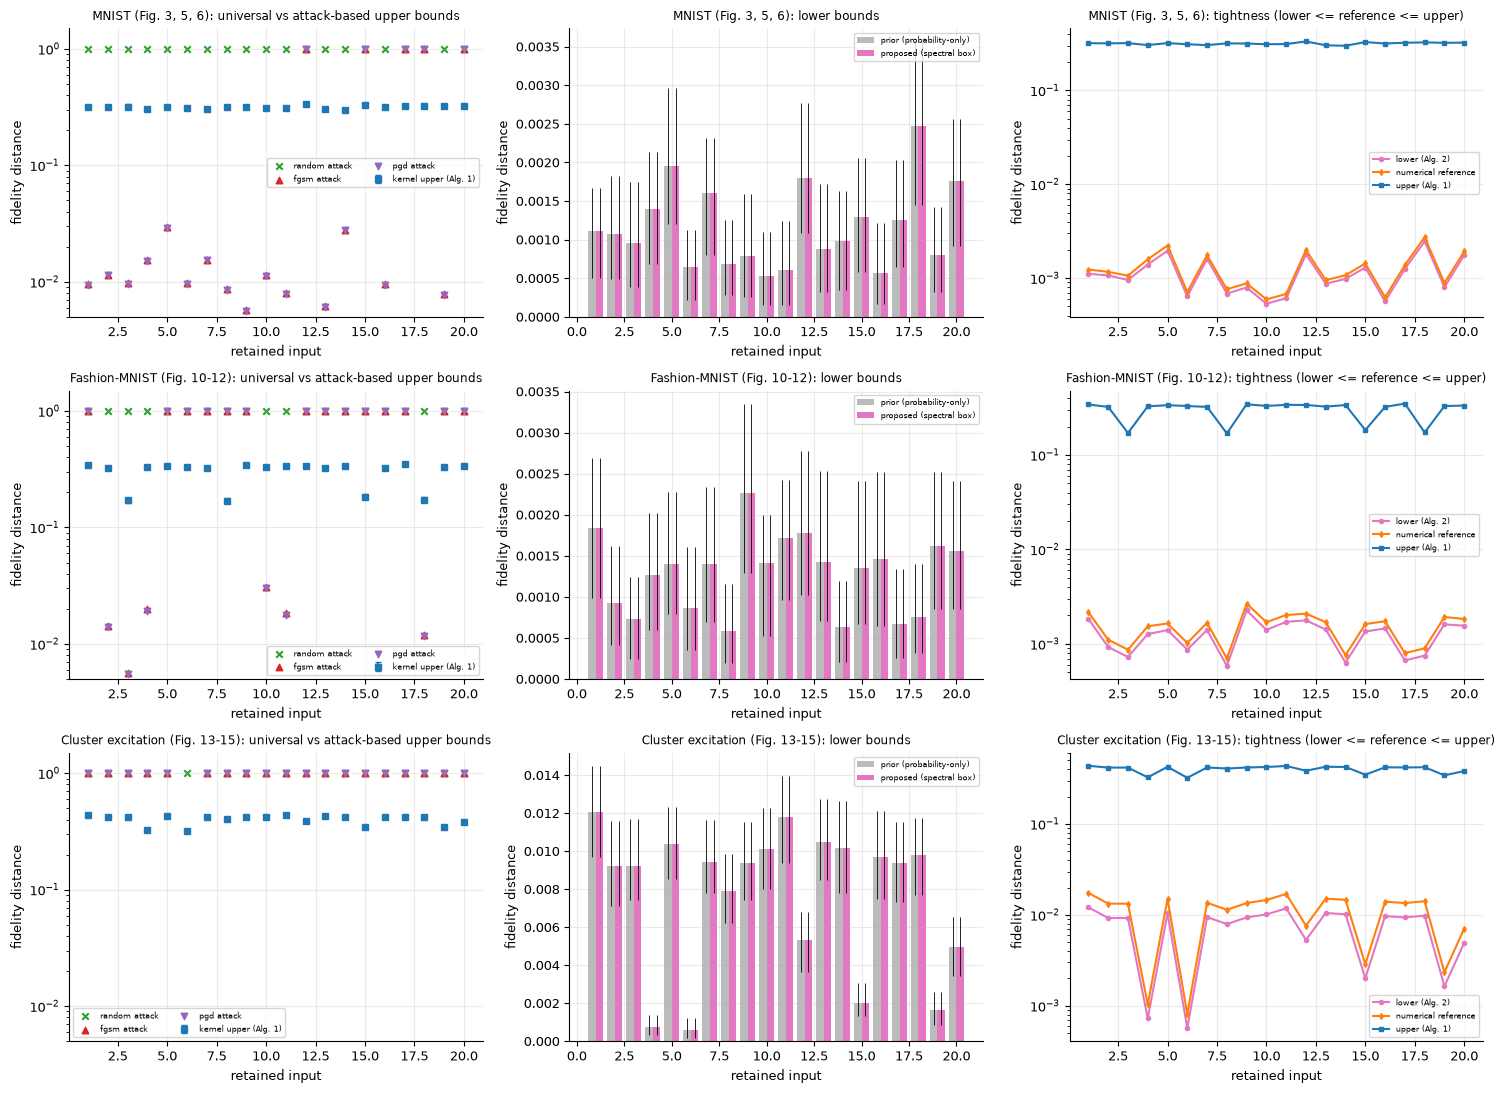

In [36]:
def plot_task_row(axes, df, name):
    x = df.plot_index.values
    ax = axes[0]
    ax.errorbar(x, df.upper, yerr=[df.upper - df.upper_lo, df.upper_hi - df.upper], fmt="s", ms=4, color="#1f77b4", capsize=2, label="kernel upper (Alg. 1)")
    for m, mk, col in (("random", "x", "#2ca02c"), ("fgsm", "^", "#d62728"), ("pgd", "v", "#9467bd")):
        v = df[f"{m}_upper"]
        if v.notna().any():
            ax.scatter(x, v, marker=mk, s=22, color=col, label=f"{m} attack")
    ax.set_yscale("log"); ax.set_ylim(5e-3, 1.5); ax.set_xlabel("retained input"); ax.set_ylabel("fidelity distance")
    ax.set_title(f"{name}: universal vs attack-based upper bounds", fontsize=8.5); ax.legend(fontsize=6, ncol=2)
    ax = axes[1]
    w = 0.4
    ax.bar(x - w / 2, df.prior_lower, w, color="#bbbbbb", label="prior (probability-only)")
    ax.bar(x + w / 2, df.lower, w, color="#e377c2", label="proposed (spectral box)")
    ax.errorbar(x - w / 2, df.prior_lower, yerr=[df.prior_lower - df.prior_lower_lo, df.prior_lower_hi - df.prior_lower], fmt="none", ecolor="k", lw=0.6)
    ax.errorbar(x + w / 2, df.lower, yerr=[df.lower - df.lower_lo, df.lower_hi - df.lower], fmt="none", ecolor="k", lw=0.6)
    ax.set_xlabel("retained input"); ax.set_ylabel("fidelity distance"); ax.set_title(f"{name}: lower bounds", fontsize=8.5); ax.legend(fontsize=6)
    ax = axes[2]
    ax.plot(x, df.lower, "o-", ms=3, color="#e377c2", label="lower (Alg. 2)")
    ax.plot(x, df.reference, "d-", ms=3, color="#ff7f0e", label="numerical reference")
    ax.plot(x, df.upper, "s-", ms=3, color="#1f77b4", label="upper (Alg. 1)")
    ax.set_yscale("log"); ax.set_xlabel("retained input"); ax.set_ylabel("fidelity distance")
    ax.set_title(f"{name}: tightness (lower <= reference <= upper)", fontsize=8.5); ax.legend(fontsize=6)

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for r, (key, name) in enumerate((("mnist", "MNIST (Fig. 3, 5, 6)"), ("fashion_mnist", "Fashion-MNIST (Fig. 10-12)"), ("cluster", "Cluster excitation (Fig. 13-15)"))):
    plot_task_row(axes[r], RES[key]["df"], name)
plt.tight_layout(); plt.show()

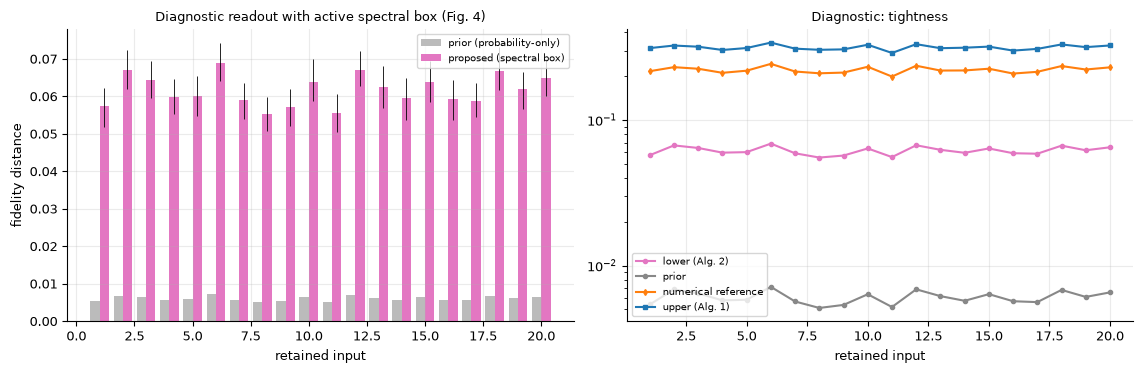

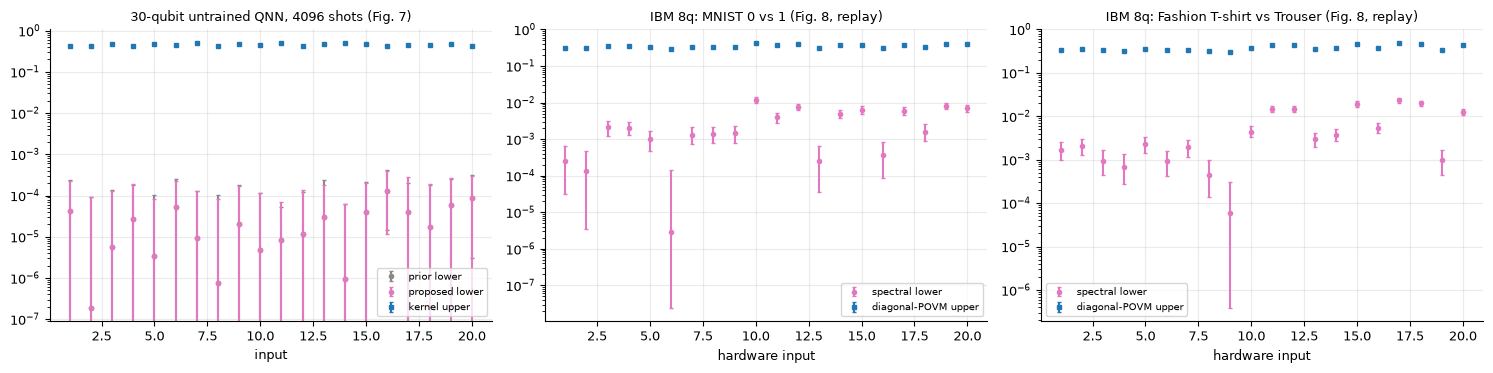

In [37]:
d = RES["lower_bound_demo"]["df"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
x = d.plot_index.values; w = 0.4
axes[0].bar(x - w / 2, d.prior_lower, w, color="#bbbbbb", label="prior (probability-only)")
axes[0].bar(x + w / 2, d.lower, w, color="#e377c2", label="proposed (spectral box)")
axes[0].errorbar(x + w / 2, d.lower, yerr=[d.lower - d.lower_lo, d.lower_hi - d.lower], fmt="none", ecolor="k", lw=0.6)
axes[0].set_xlabel("retained input"); axes[0].set_ylabel("fidelity distance")
axes[0].set_title("Diagnostic readout with active spectral box (Fig. 4)", fontsize=9); axes[0].legend(fontsize=7)
axes[1].plot(x, d.lower, "o-", ms=3, color="#e377c2", label="lower (Alg. 2)"); axes[1].plot(x, d.prior_lower, "o-", ms=3, color="#888888", label="prior")
axes[1].plot(x, d.reference, "d-", ms=3, color="#ff7f0e", label="numerical reference"); axes[1].plot(x, d.upper, "s-", ms=3, color="#1f77b4", label="upper (Alg. 1)")
axes[1].set_yscale("log"); axes[1].set_xlabel("retained input"); axes[1].set_title("Diagnostic: tightness", fontsize=9); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
floor = 1e-7
x = ST.plot_index.values
axes[0].errorbar(x, np.maximum(ST.prior_lower, floor), yerr=[np.maximum(ST.prior_lower - ST.prior_lo, 0), np.maximum(ST.prior_hi - ST.prior_lower, 0)], fmt="o", ms=3, color="#888888", label="prior lower", capsize=1.5)
axes[0].errorbar(x, np.maximum(ST.lower, floor), yerr=[np.maximum(ST.lower - ST.lower_lo, 0), np.maximum(ST.lower_hi - ST.lower, 0)], fmt="o", ms=3, color="#e377c2", label="proposed lower", capsize=1.5)
axes[0].errorbar(x, ST.upper, yerr=[np.maximum(ST.upper - ST.upper_lo, 0), np.maximum(ST.upper_hi - ST.upper, 0)], fmt="s", ms=3, color="#1f77b4", label="kernel upper", capsize=1.5)
axes[0].set_yscale("log"); axes[0].set_xlabel("input"); axes[0].set_title("30-qubit untrained QNN, 4096 shots (Fig. 7)", fontsize=9); axes[0].legend(fontsize=7)
for ax, (t_, nm) in zip(axes[1:], (("mnist_0_vs_1", "IBM 8q: MNIST 0 vs 1"), ("fashion_0_vs_1", "IBM 8q: Fashion T-shirt vs Trouser"))):
    h = HW[HW.task == t_].reset_index(drop=True); xx = np.arange(1, len(h) + 1)
    ax.errorbar(xx, np.maximum(h.lower, floor), yerr=[np.maximum(h.lower - h.lower_lo, 0), np.maximum(h.lower_hi - h.lower, 0)], fmt="o", ms=3, color="#e377c2", label="spectral lower", capsize=1.5)
    ax.errorbar(xx, h.upper, yerr=[np.maximum(h.upper - h.upper_lo, 0), np.maximum(h.upper_hi - h.upper, 0)], fmt="s", ms=3, color="#1f77b4", label="diagonal-POVM upper", capsize=1.5)
    ax.set_yscale("log"); ax.set_xlabel("hardware input"); ax.set_title(nm + " (Fig. 8, replay)", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Side-by-side comparison with the paper

Every number in the paper that this notebook can test is listed with its verdict. Rules: accuracies and attack-success rates are "reproduced" within 2 accuracy points (10 percentage points for success rates over 20 inputs, because PGD uses a random start); bounds are "reproduced" within 1% relative (5% when the paper prints only two significant digits); counts and orderings must match exactly. Items that need the physical device (or are statements about the authors' server) are marked "cannot be checked". Rows that need a full-size run say so in FAST mode.

In [38]:
CLAIMS = []
def claim(cid, text, paper, ours, kind, tol=0.01):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        v, shown = "cannot be checked", "-"
    elif kind == "acc":
        gap = ours - paper; v = "reproduced" if abs(gap) <= tol + 1e-9 else ("exceeded" if gap > 0 else "not reached"); shown = f"{ours:.4f}"
    elif kind == "rel":
        gap = (ours - paper) / abs(paper); v = "reproduced" if abs(gap) <= tol else f"differs by {gap:+.1%}"; shown = f"{ours:.5g}"
    elif kind == "pct":
        gap = ours - paper; v = "reproduced" if abs(gap) <= tol + 1e-9 else ("exceeded" if gap > 0 else "not reached"); shown = f"{ours:.0%}"
    elif kind == "exact":
        v = "reproduced" if ours == paper else f"differs ({ours} vs {paper})"; shown = str(ours)
    elif kind == "near":
        v = "reproduced" if abs(ours - paper) <= tol else f"differs ({ours} vs {paper})"; shown = str(ours)
    elif kind == "bool":
        v = "reproduced" if bool(ours) == bool(paper) else "not reproduced"; shown = str(bool(ours))
    else:
        raise ValueError(kind)
    paper_s = (f"{paper:.0%}" if kind == "pct" else f"{paper:.5g}") if isinstance(paper, (int, float)) and not isinstance(paper, bool) else str(paper)
    CLAIMS.append(dict(id=cid, claim=text, paper=paper_s, notebook=shown, verdict=v))

S_ = {k: RES[k]["summary"] for k in RES}
full = lambda k: S_[k]["n_attacked"] >= N_RETAIN                                   # attack statistics need all 20 inputs
claim("A1", "MNIST test accuracy (frozen model, Sec. 6)", 0.915, S_["mnist"]["accuracy"], "acc", 0.02)
claim("A2", "Fashion-MNIST test accuracy", 0.8525, S_["fashion_mnist"]["accuracy"], "acc", 0.02)
claim("A3", "Cluster-excitation test accuracy", 0.995, S_["cluster"]["accuracy"], "acc", 0.02)
claim("A4", "Lower-bound diagnostic model accuracy", 0.275, S_["lower_bound_demo"]["accuracy"], "acc", 0.02)
claim("A5", "MNIST accuracy of OUR retrained model (artifact schedule; paper gives no epochs / lr)", 0.915, TRAINED["artifact config"]["acc_povm"] if not FAST_MODE else None, "acc", 0.02)
claim("A6a", "8-qubit MNIST 0-vs-1 QNN test accuracy (from stored weights + images)", 0.98, acc8["mnist_0_vs_1"], "acc", 0.02)
claim("A6b", "8-qubit Fashion T-shirt-vs-Trouser QNN test accuracy", 0.905, acc8["fashion_0_vs_1"], "acc", 0.02)
claim("B1", "MNIST mean kernel upper bound", 0.3166, S_["mnist"]["upper_mean"], "rel", 0.01)
claim("B2", "Fashion-MNIST mean kernel upper bound", 0.3019, S_["fashion_mnist"]["upper_mean"], "rel", 0.01)
claim("B3", "Cluster mean kernel upper bound", 0.4007, S_["cluster"]["upper_mean"], "rel", 0.01)
claim("B4", "MNIST mean lower bound", 1.1583e-3, S_["mnist"]["lower_mean"], "rel", 0.01)
claim("B5", "Fashion-MNIST mean lower bound", 1.2822e-3, S_["fashion_mnist"]["lower_mean"], "rel", 0.01)
claim("B6", "Cluster mean lower bound", 7.7161e-3, S_["cluster"]["lower_mean"], "rel", 0.01)
claim("B7", "MNIST mean numerical reference (printed as 0.0013)", 0.0013, S_["mnist"]["reference_mean"], "rel", 0.05)
claim("B8", "Diagnostic mean proposed lower bound", 6.16499e-2, S_["lower_bound_demo"]["lower_mean"], "rel", 0.01)
claim("B9", "Diagnostic mean probability-only lower bound", 6.04775e-3, S_["lower_bound_demo"]["prior_mean"], "rel", 0.01)
claim("B10", "Diagnostic ratio of mean bounds", 10.194, S_["lower_bound_demo"]["lower_mean"] / S_["lower_bound_demo"]["prior_mean"], "rel", 0.01)
claim("B11", "Diagnostic: proposed bound strictly larger on all 20 inputs", 20, S_["lower_bound_demo"]["strict_improvements"], "exact")
claim("B12", "Standard models: spectral and probability-only bounds coincide on all 20 inputs (3 tasks)", True,
      all(S_[k]["equal_to_prior_all"] for k in ("mnist", "fashion_mnist", "cluster")), "bool")
claim("B13", "lower <= numerical reference <= upper on every retained input (3 tasks + diagnostic)", True, all(S_[k]["ordered"] for k in ("mnist", "fashion_mnist", "cluster", "lower_bound_demo")), "bool")
claim("B14", "Kernel upper bound non-trivial (< 1) on all 20 inputs (3 tasks)", 60, sum(S_[k]["upper_nontrivial"] for k in ("mnist", "fashion_mnist", "cluster")), "exact")
claim("B15a", "MNIST: 20 retained of 31 traversed candidates", 31, S_["mnist"]["traversed"], "exact")
claim("B15b", "Fashion-MNIST: 20 retained of 35", 35, S_["fashion_mnist"]["traversed"], "exact")
claim("B15c", "Cluster: 20 retained of 24", 24, S_["cluster"]["traversed"], "exact")
claim("C1", "MNIST FGSM success rate", 0.75, S_["mnist"]["fgsm_rate"] if full("mnist") else None, "pct", 0.10)
claim("C2", "MNIST PGD success rate", 0.80, S_["mnist"]["pgd_rate"] if full("mnist") else None, "pct", 0.10)
claim("C3", "MNIST random-search success rate", 0.0, S_["mnist"]["random_rate"] if full("mnist") else None, "pct", 0.10)
claim("C4", "Fashion-MNIST FGSM success rate", 0.30, S_["fashion_mnist"]["fgsm_rate"] if full("fashion_mnist") else None, "pct", 0.10)
claim("C5", "Fashion-MNIST PGD success rate", 0.30, S_["fashion_mnist"]["pgd_rate"] if full("fashion_mnist") else None, "pct", 0.10)
claim("C6", "Fashion-MNIST random-search success rate", 0.0, S_["fashion_mnist"]["random_rate"] if full("fashion_mnist") else None, "pct", 0.10)
claim("C7", "Cluster: no attack (random / FGSM / PGD) finds a witness (max success rate)", 0.0,
      max(S_["cluster"][m] for m in ("random_rate", "fgsm_rate", "pgd_rate")) if full("cluster") else None, "pct", 0.0)
claim("D1", "Example 4.9 upper bound", 0.368, rub_ex, "rel", 0.01)
claim("D2", "Example 5.4 spectral-box lower bound", 7.21e-3, rlb_ex, "rel", 0.01)
claim("D3", "Example 5.4 probability-only bound", 2.55e-3, prior_ex, "rel", 0.01)
claim("D4", "Example 5.4 exact QCQP radius", 0.120, exact_ex, "rel", 0.01)
claim("E1", "30-qubit mean lower bound", 2.966e-5, ST.lower.mean(), "rel", 0.01)
claim("E2", "30-qubit mean kernel upper bound", 0.4549, ST.upper.mean(), "rel", 0.01)
claim("E3", "30-qubit lower <= upper on all 20 inputs; spectral == probability-only", True, bool((ST.lower <= ST.upper).all() and ((ST.lower - ST.prior_lower).abs() < 1e-12).all()), "bool")
claim("E4", "30-qubit intervals with zero lower endpoint (probability-only), of 20", 17, int((ST.prior_lo <= 0).sum()), "near", 3)
claim("E5", "30-qubit intervals with zero lower endpoint (spectral), of 20", 18, int((ST.lower_lo <= 0).sum()), "near", 3)
for t_, nm, lo_p, up_p, keep_p in (("mnist_0_vs_1", "MNIST", 0.0034, 0.3513, 0.95), ("fashion_0_vs_1", "Fashion", 0.0066, 0.3747, 1.0)):
    h = HW[HW.task == t_]
    claim(f"F1{nm[0]}", f"IBM replay, {nm}: mean spectral lower bound", lo_p, h.lower.mean(), "rel", 0.02)
    claim(f"F2{nm[0]}", f"IBM replay, {nm}: mean diagonal-POVM upper bound", up_p, h.upper.mean(), "rel", 0.01)
    claim(f"F3{nm[0]}", f"IBM replay, {nm}: hardware preserves the ideal label (conditional rate)", keep_p, float(h.hw_correct.mean()), "pct", 1e-9)
claim("F4", "IBM replay: eps_RLB <= eps_RUB on every one of the 40 circuits", True, bool((HW.lower <= HW.upper).all()), "bool")
claim("F5", "40 circuits executed on ibm_kingston with 4096 shots (job d9vf8ql0vrcc73bp5kt0)", "executed", None, "bool")
claim("F6", "Certificates are robust to device noise / calibration drift (paper: NOT claimed)", "not claimed", None, "bool")
claim("G1", "Evaluation timing on the authors' 256-core server (Sec. 6)", "lightweight", None, "bool")
CMP = pd.DataFrame(CLAIMS)
pd.set_option("display.max_colwidth", 95); pd.set_option("display.width", 200)
print(CMP.to_string(index=False))
print("\nverdict counts:", CMP.verdict.str.replace(r"differs.*", "differs", regex=True).value_counts().to_dict())
# any attack success on the cluster task contradicts "no attack finds a witness": show exactly which input and how close it is
art_c = pd.read_csv(REPO / "results" / "cluster" / "robustness_results.csv").set_index("sample_idx")
dfc = RES["cluster"]["df"]
for _, r in dfc[(dfc.fgsm_success == 1) | (dfc.pgd_success == 1) | (dfc.random_success == 1)].iterrows():
    a_row = art_c.loc[int(r.sample_idx)]
    print(f"note on C7: cluster input {int(r.sample_idx)}: closest attack witness at distance {min(r.fgsm_upper, r.pgd_upper, r.random_upper):.2e} "
          f"(exact reference {r.reference:.2e}, lower {r.lower:.2e}, kernel upper {r.upper:.3f}) - a valid witness, above the reference; "
          f"the artifact's released attack run on this input: FGSM success = {bool(a_row.fgsm_attack_success)}, PGD success = {bool(a_row.pgd_attack_success)}")

  id                                                                                     claim       paper   notebook           verdict
  A1                                                MNIST test accuracy (frozen model, Sec. 6)       0.915     0.9150        reproduced
  A2                                                               Fashion-MNIST test accuracy      0.8525     0.8525        reproduced
  A3                                                          Cluster-excitation test accuracy       0.995     0.9950        reproduced
  A4                                                     Lower-bound diagnostic model accuracy       0.275     0.2750        reproduced
  A5     MNIST accuracy of OUR retrained model (artifact schedule; paper gives no epochs / lr)       0.915     0.8950       not reached
 A6a                     8-qubit MNIST 0-vs-1 QNN test accuracy (from stored weights + images)        0.98     0.9800        reproduced
 A6b                                      8-qubi

## Reading the paper critically

* **The sandwich is wide and the two sides are different kinds of objects.** On the standard models the lower bound is about 1e-3 and the upper bound about 0.3 (paper: 0.0012 vs 0.3166), so the certified region is tiny and the witness radius is two orders of magnitude larger. The numerical reference sits next to the lower bound, which says the lower bound is nearly tight, while the kernel upper bound is loose: FGSM/PGD, which need gradients and are stronger than KRQA, find witnesses at radii of order 1e-2 on most MNIST inputs. The upper bound's value is that it exists without any attack search, not that it is tight.
* **The headline improvement (spectral box) is inactive on every standard model.** The proposed and probability-only bounds are identical on MNIST, Fashion-MNIST, cluster and the 30-qubit run; strict improvement appears only on a separate, specially trained 27.5%-accuracy model with a hand-built amplified readout (the paper says so openly). For an orthogonal projective readout the spectral boxes are vacuous by construction, so the improvement requires a deliberately non-projective, non-uniform readout.
* **The readouts in the standard experiments are chosen, not given.** The randomized-basis POVMs (strengths 0.05, 0.10, 0.15 with specific seeds) are classical post-processing added on top of the native computational-basis readout, and the artifact's configuration records that they were fixed before the certificates were evaluated. The certified statements are therefore about the *declared* classifier `Q = (U, POVM)`, not about the bare QNN; the hardware experiment makes this explicit.
* **Reported statistics are conditional.** The 20 inputs are the first correctly classified ones (seeded order) with both bounds above 5e-4; 11 of 31 MNIST candidates, 15 of 35 Fashion-MNIST and 4 of 24 cluster candidates are excluded. Means over those 20 are not population robustness rates, and the hardware inputs are additionally restricted to ideal-correct, class-balanced samples.
* **"No attack finds a witness" is budget-dependent.** For the cluster task the paper reports that random search, FGSM and PGD all fail; in our run, with the artifact's attack settings, FGSM and PGD succeed on one borderline input whose exact radius is only about 8e-4 (see the note printed under the comparison table), while the artifact's released attack run fails on it. Attack success near the radius of the closest witness is sensitive to step sizes, random starts and floating-point details, which is exactly why an attack-independent certificate is attractive.
* **Finite shots break the guarantee, honestly acknowledged.** The theorems hold for the underlying probabilities; with 4096 shots the standard error of a probability is about 0.008, far larger than the 1e-3 margins that give rise to the lower bounds. The paper's own 30-qubit intervals have a zero lower endpoint for 17-18 of 20 inputs, and its "95% intervals" are sampling variability, not a coverage guarantee.
* **The upper bound needs more than labels.** It needs binary projector readouts derived from the published effects (one extra run per competitor); a label-only API supports only the lower bound.
* **Unitary evolution is assumed.** The IBM proof of concept applies the same post-processing to noisy counts and checks only that the lower bound stays below the upper bound; the pairs are not certificates for the physical noisy channel. Hardware label preservation (95% for MNIST) shows how close to ties these inputs are.
* **Framework statements are inconsistent.** The abstract/keywords point to Qiskit and TensorFlow Quantum, while the experiments (and the artifact) use PennyLane for the 10-qubit models, Qiskit only for the 30-qubit and hardware runs. The corpus index also lists a "HAI" dataset for this paper; the paper uses none.
* **Reproducibility is strong where the artifact is used, weaker from the text alone.** With the frozen checkpoints, POVMs and seeds every table is recovered to within numerical noise; from the text alone, the readouts, epochs, learning rate, attack budgets and sampling seed are all missing, and our own training with the artifact's schedule (lr 0.03, 20 epochs) lands about two accuracy points below the paper's 91.5% (the exact value depends on the seed), and a faster schedule does not help.

## Exercises

1. **Projective vs non-projective readout.** Set the randomized-basis strength of the MNIST readout to 0 (a projective computational-basis measurement) and recompute the 20-input table. Show that the spectral box becomes vacuous (`lower == prior`) and describe how the upper bound changes.
2. **Shots and Hoeffding.** Vary `SHOTS` from 1e3 to 1e5 in `certify_krqa` for a few inputs and plot the error of the estimated upper bound against `N`. Compare the slope with the `1/sqrt(N)` prediction of Theorem 4.8 and find the `N` at which the lower bound of a typical MNIST input is larger than its own sampling standard deviation.
3. **Engineer a strict improvement.** Search random diagonal POVMs (as in the soundness test) for the readout and probability vector that maximise `lower / prior`. What do the spectral boxes of the best readouts look like, and how realistic is such a readout for a hardware QNN?
4. **Attack vs witness.** Increase the PGD iterations and the budgets in `ATTACK_EPS` until the best PGD witness approaches the numerical reference. How many gradient evaluations does that take, and what does this say about the usefulness of a 0.3 kernel upper bound?
5. **Outside the theory.** Add depolarising noise inside `KRQAService.run` (mix the reduced state with `I/d`) and re-run `certify_krqa`. How often does the estimated `eps_RLB` exceed the noise-free reference, and why is that not a counterexample to the theorem?

In [39]:
print(f"total wall-clock time of this run: {(time.time() - T0) / 60:.1f} minutes  (FAST_MODE={FAST_MODE})")

total wall-clock time of this run: 71.6 minutes  (FAST_MODE=False)
